# 03 — Formulación y validación de hipótesis

Fases 2 y 6 del proyecto. Aquí planteamos las hipótesis con su H0 y H1, las justificamos desde el negocio y las validamos con pruebas estadísticas usando el valor p para tomar decisiones.

## 1. Formulación de hipótesis

En esta parte planteamos las hipótesis que vamos a validar. Las pensamos desde el lugar de una productora con un capital limitado que tiene que decidir en qué películas meterlo. En el notebook 01 partimos esa decisión en tres preguntas clave:

1. **¿Cuánto invertir?** Si meterle más presupuesto a una película hace que rinda más.
2. **¿Cuándo estrenar?** Si la fecha de estreno cambia el retorno.
3. **¿Qué tipo de película hacer?** Si el género influye en que la película dé plata.

De cada pregunta sale una hipótesis, y para cada una escogimos una de las pruebas de las guías del curso: correlación (semana 4), t de Student y chi-cuadrado (semana 6). Antes de plantear cada hipótesis miramos los datos para ver si hay un patrón que valga la pena probar.

Aquí **todavía no corremos las pruebas**, solo las planteamos. Para explorar usamos los datos limpios y las variables que dejamos listas en el notebook 02.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import seaborn as sns

sns.set_theme(style="whitegrid")

PROCESSED = Path("../data/processed")

UMBRAL_RENTABLE = 2
MESES_TEMPORADA_ALTA = [5, 6, 7, 8, 11, 12]

MESES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
AZUL, GRIS = "#2b6cb0", "#a0aec0"
FORMATO_MILLONES = FuncFormatter(lambda valor, _: f"{valor / 1e6:g}")

### 1.1 Datos para la exploración

Partimos de `peliculas_variables.csv`, el archivo que dejamos en el notebook 02 con los datos limpios y las variables derivadas, y nos quedamos con las películas de la base financiera (`base_financiera`):

- Ya estrenadas (`status = Released`).
- Con presupuesto y recaudación reportados. Los ceros de `budget` y `revenue` eran datos que nadie reportó, y en la limpieza quedaron como faltantes.
- Sin montos menores a 10.000 dólares (`monto_dudoso`). Hay presupuestos de 1, 7 o 25 dólares que están mal digitados, y como el retorno se calcula dividiendo por el presupuesto, una sola de esas filas da retornos absurdos.

In [2]:
peliculas = pd.read_csv(PROCESSED / "peliculas_variables.csv", parse_dates=["release_date"],
                        dtype={"anio": "Int64", "mes": "Int64",
                               "temporada_alta": "boolean", "rentable": "boolean"})
finanzas = peliculas[peliculas["base_financiera"]].copy()

reportadas = peliculas["estrenada"] & peliculas["budget"].notna() & peliculas["revenue"].notna()
print(f"Estrenadas con presupuesto y recaudación: {reportadas.sum():,}")
print(f"De esas, con algún monto menor a 10.000 USD: {(reportadas & peliculas['monto_dudoso']).sum()}")
print(f"Películas para la exploración: {len(finanzas):,}")

Estrenadas con presupuesto y recaudación: 3,228
De esas, con algún monto menor a 10.000 USD: 24
Películas para la exploración: 3,204


**¿Qué vemos?** Los 24 casos que quedan por fuera los revisamos uno por uno en el diagnóstico del notebook 02 (sección 1.7). La mayoría son errores evidentes: *Angela's Ashes* aparece con 25 dólares de presupuesto y *Death at a Funeral* con 46 dólares de recaudación, cuando seguramente eran millones. Otros sí pueden ser reales. *Primer* (7.000 dólares) y *Tarnation* (218) son conocidas justamente por lo baratas, pero recaudaron 60 y más de 5.000 veces su presupuesto, y esos multiplicadores se comerían cualquier promedio. Y casos como *The Adventurer* (25 millones de presupuesto y 6.399 dólares de recaudación) pueden ser fracasos de verdad con un estreno muy limitado. Al sacarlas perdemos unos pocos fracasos reales, pero son 24 de 3.228 películas, menos del 1 %, así que el panorama no cambia.

Las tres hipótesis usan dos variables que creamos en el notebook 02 (sección 3.2):

- **Multiplicador** = `revenue / budget`: cuántas veces recuperó la película lo que costó. Es lo mismo que ROI + 1, pero se lee más fácil ("recaudó 2,5 veces su presupuesto"). Tiene otra ventaja: como el presupuesto y la recaudación están en dólares del mismo año, la inflación casi no lo afecta.
- **Rentable**: si el multiplicador es 2 o más. No basta con recaudar lo mismo que costó, porque de la taquilla una buena parte se la quedan las salas y los distribuidores, y el presupuesto que se reporta normalmente no incluye la publicidad. Recaudar el doble del presupuesto es una regla aproximada que se usa mucho en análisis de taquilla para estimar el punto de equilibrio (no sale de las guías del curso).

In [3]:
assert finanzas["rentable"].eq(finanzas["multiplicador"].ge(UMBRAL_RENTABLE)).all()

print(f"Rentables (multiplicador >= {UMBRAL_RENTABLE}):  {finanzas['rentable'].mean():.1%}")
print(f"Recaudaron más de lo que costaron: {(finanzas['multiplicador'] > 1).mean():.1%}")

Rentables (multiplicador >= 2):  56.2%
Recaudaron más de lo que costaron: 75.8%


Con el criterio de 2x, un poco más de la mitad de las películas son rentables; si solo pidiéramos recaudar más de lo que costaron, serían tres de cada cuatro. La diferencia es grande, y por eso dejamos explícito qué estamos llamando "rentable": cambiar el umbral cambia los resultados.

Hay que tener presente que esta base no es una muestra al azar. Son las películas que sí reportaron cifras, que tienden a ser las más comerciales. Eso afecta a las tres hipótesis y lo retomamos en las limitaciones.

Para comparar grupos en las tres hipótesis usamos siempre el mismo resumen:

In [4]:
def resumir(datos, por):
    tabla = datos.groupby(por, observed=True).agg(
        peliculas=("multiplicador", "size"),
        presupuesto_mediano=("budget", "median"),
        multiplicador_mediano=("multiplicador", "median"),
        rentables=("rentable", "mean"),
    )
    tabla["presupuesto_mediano"] /= 1e6
    tabla["rentables"] *= 100
    return tabla.round(1).rename(columns={
        "peliculas": "Películas",
        "presupuesto_mediano": "Presupuesto mediano (M USD)",
        "multiplicador_mediano": "Multiplicador mediano",
        "rentables": "% rentables",
    })

Usamos medianas y no promedios porque el multiplicador está muy sesgado a la derecha: unas pocas películas que recaudaron 50 o 100 veces su presupuesto subirían el promedio de cualquier grupo.

### 1.2 Criterios para las tres pruebas

- **Nivel de significancia α = 0,05.** Es el valor estándar, y aquí un error tipo I no es tan grave como en medicina: lo peor que pasa es que la productora cambie su estrategia por un efecto que no existe. Las consecuencias de cada tipo de error las resumimos al final.
- **Pruebas bilaterales.** En los tres casos el efecto podría ir para cualquier lado (lo explicamos en cada hipótesis), así que no nos amarramos a una dirección antes de correr la prueba.
- **El valor p no es suficiente.** Con más de 3.000 películas, casi cualquier diferencia sale significativa. Por eso, además del valor p, vamos a reportar qué tan grande es el efecto y si esa magnitud le importa al negocio.
- **No "aceptamos" H0.** Si el valor p es mayor que α, decimos que no hay evidencia suficiente para rechazarla.

### 1.3 Hipótesis 1: presupuesto y rentabilidad

**Pregunta de negocio:** ¿meterle más plata a una película hace que rinda más?

Que una película más cara recaude más es casi obvio: tiene más estrellas, más efectos y más publicidad. Pero a una productora con capital limitado no le interesa solo cuánto entra, sino cuánto rinde cada dólar que invierte. Por eso cruzamos el presupuesto con el multiplicador y no con la recaudación.

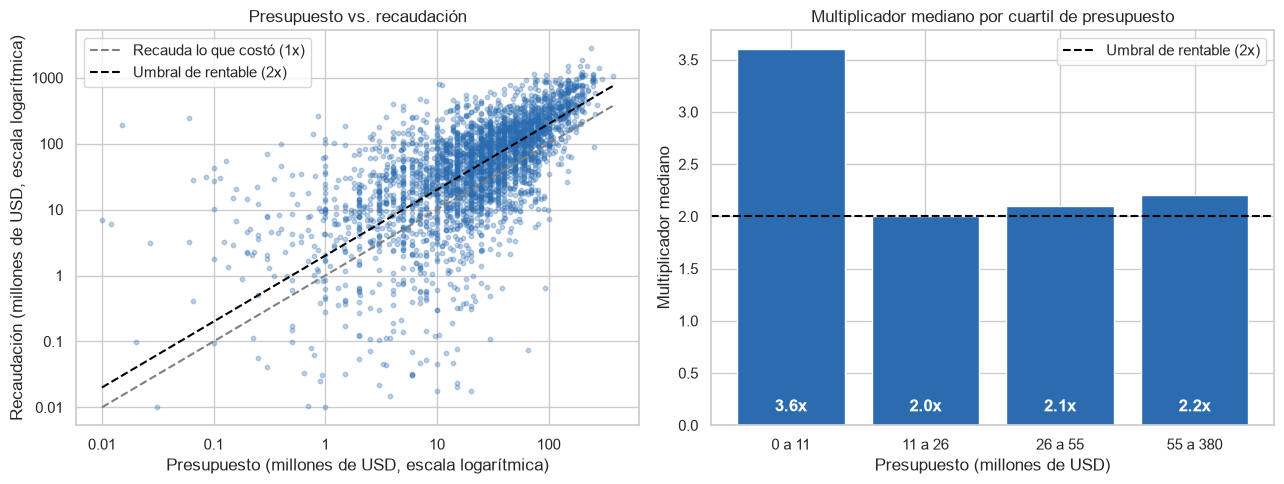

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
Presupuesto (M USD),,,,
0 a 11,826,5.0,3.6,65.6
11 a 26,776,18.0,2.0,51.2
26 a 55,817,38.0,2.1,51.5
55 a 380,785,85.0,2.2,56.2


In [5]:
cortes = finanzas["budget"].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
etiquetas = [f"{inicio / 1e6:.0f} a {fin / 1e6:.0f}" for inicio, fin in zip(cortes[:-1], cortes[1:])]
cuartil_presupuesto = pd.cut(finanzas["budget"], cortes, labels=etiquetas, include_lowest=True)
por_cuartil = resumir(finanzas, cuartil_presupuesto).rename_axis("Presupuesto (M USD)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.scatter(finanzas["budget"], finanzas["revenue"], s=10, alpha=0.3, color=AZUL)
extremos = [finanzas["budget"].min(), finanzas["budget"].max()]
ax1.plot(extremos, extremos, color="gray", linestyle="--", linewidth=1.5,
         label="Recauda lo que costó (1x)")
ax1.plot(extremos, [UMBRAL_RENTABLE * x for x in extremos], color="black", linestyle="--",
         linewidth=1.5, label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.xaxis.set_major_formatter(FORMATO_MILLONES)
ax1.yaxis.set_major_formatter(FORMATO_MILLONES)
ax1.set_title("Presupuesto vs. recaudación")
ax1.set_xlabel("Presupuesto (millones de USD, escala logarítmica)")
ax1.set_ylabel("Recaudación (millones de USD, escala logarítmica)")
ax1.legend(loc="upper left")

ax2.bar(por_cuartil.index, por_cuartil["Multiplicador mediano"], color=AZUL)
ax2.axhline(UMBRAL_RENTABLE, color="black", linestyle="--", linewidth=1.5,
            label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
for i, valor in enumerate(por_cuartil["Multiplicador mediano"]):
    ax2.text(i, 0.1, f"{valor:.1f}x", ha="center", va="bottom", color="white", fontweight="bold")
ax2.set_title("Multiplicador mediano por cuartil de presupuesto")
ax2.set_xlabel("Presupuesto (millones de USD)")
ax2.set_ylabel("Multiplicador mediano")
ax2.legend()

plt.tight_layout()
plt.show()

por_cuartil

**¿Qué vemos?** A la izquierda, la recaudación sí sube con el presupuesto: la nube va en diagonal. De 10 millones para arriba va casi paralela a las líneas de 1x y 2x, o sea que las películas más caras no se alejan más del umbral que las de presupuesto medio. Por debajo de 10 millones la nube se abre mucho: hay películas que recaudaron cien veces o más lo que costaron y otras que casi no recaudaron nada, así que hacer cine barato también es más incierto. A la derecha se ve mejor: el cuarto de películas más baratas (hasta 11 millones) tiene un multiplicador mediano de 3,6 y el 66 % son rentables, mientras que en los otros tres cuartiles el multiplicador se queda alrededor de 2 y los rentables entre 51 % y 56 %. Si hay relación, sería negativa y no lineal: el cambio está entre las películas baratas y el resto.

Antes de plantear la hipótesis revisamos algo que nos hizo dudar. El presupuesto está en dólares de cada año, sin ajustar por inflación, y las películas viejas del dataset tienen presupuestos nominales muy bajos. Si además son sobre todo clásicos exitosos, quedarían todas en el cuartil barato con multiplicadores altos:

In [6]:
periodo = pd.cut(finanzas["anio"], [1900, 1979, 1989, 1999, 2009, 2017],
                 labels=["Antes de 1980", "1980-1989", "1990-1999", "2000-2009", "2010-2017"])
resumir(finanzas, periodo).rename_axis("Periodo de estreno")

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
Periodo de estreno,,,,
Antes de 1980,200,3.0,5.5,84.0
1980-1989,204,13.9,4.0,70.1
1990-1999,535,30.0,2.1,53.1
2000-2009,1324,30.0,2.0,49.7
2010-2017,941,30.0,2.4,58.2


**¿Qué vemos?** Se confirma la duda. Las películas de antes de 1980 tienen un presupuesto mediano de 3 millones y las de los 80 de 14, contra 30 millones desde los 90. Al mismo tiempo, sus multiplicadores medianos son de 5,5 y 4,0, con 84 % y 70 % de rentables, mientras que desde los 90 el multiplicador ronda 2. Esas películas viejas no llegaron al dataset por azar: es mucho más probable que TMDB tenga las cifras de un clásico que de una película de 1975 que nadie recuerda. Entonces parte de la ventaja del cuartil barato puede ser un efecto de la época y no del presupuesto.

Por eso la prueba se corre dos veces: sobre toda la base y solo con las películas desde 2000, donde los presupuestos son comparables entre sí. Otra opción sería ajustar los montos por inflación, pero eso no está en las guías y tampoco resolvería el sesgo de los clásicos.

**Hipótesis 1**

- **H0:** no hay correlación entre el presupuesto y el multiplicador (ρ = 0).
- **H1:** sí hay correlación entre el presupuesto y el multiplicador (ρ ≠ 0).

**Variables:** `budget` (cuantitativa continua) y `multiplicador` (cuantitativa continua, derivada de `revenue / budget`). Para el control por época, el año de estreno (`anio`).

**Prueba prevista:** correlación de Spearman con su prueba de significancia. No usamos Pearson por lo que vimos en la guía de la semana 4: Pearson solo mide relaciones lineales y es sensible a los valores extremos, y aquí tenemos un multiplicador muy sesgado y una relación que, si existe, no es lineal. Spearman trabaja con los rangos, así que además da lo mismo usar el multiplicador o el ROI. Es bilateral porque la relación podría ir para los dos lados: más presupuesto puede traer estrellas y publicidad que suben el retorno, o puede tener rendimientos decrecientes.

**Supuestos a verificar:**

- Que la relación sea monótona, lo que revisamos con la gráfica de dispersión sobre los datos limpios.
- Que las observaciones sean independientes: cada película aparece una sola vez.
- Que los montos estén bien limpios. Como el multiplicador divide por el presupuesto, un presupuesto mal digitado (muy bajo) infla el multiplicador y crea una correlación negativa artificial.

**Qué haríamos con el resultado:**

- Si se rechaza H0 con ρ negativo y se mantiene desde 2000, la productora no debería asumir que más presupuesto es mejor negocio, y tendría sentido repartir el capital en varias películas de menor presupuesto en vez de apostarlo todo a una grande.
- Si se rechaza con ρ positivo, las producciones grandes además de recaudar más rinden más por dólar, y concentrar la inversión tendría respaldo.
- Si no se rechaza, o si la correlación desaparece desde 2000, el presupuesto por sí solo no dice nada del retorno, y la decisión de cuánto invertir se tendría que apoyar en otras variables, como las de las hipótesis 2 y 3.

**Lo que no va a poder decir:** aunque salga una correlación, no prueba que bajar el presupuesto suba el retorno. Las películas baratas y las caras se diferencian en muchas otras cosas (género, productora, distribución). Y en las baratas es donde más pesa el sesgo de selección: una película pequeña que fracasó tiene menos probabilidad de reportar su taquilla que un *blockbuster* que fracasó.

### 1.4 Hipótesis 2: temporada de estreno

**Pregunta de negocio:** ¿estrenar en temporada alta mejora el retorno?

La fecha de estreno es de las pocas decisiones que la productora o la distribuidora todavía puede tomar cuando la película ya está hecha. Casi el 94 % de las películas del dataset son en inglés (notebook 01), es decir, cine pensado sobre todo para el mercado de Estados Unidos, así que definimos la temporada alta con el calendario de allá:

- **Verano:** de mayo a agosto, cuando los estudiantes están de vacaciones.
- **Fin de año:** noviembre y diciembre (Acción de Gracias y Navidad).

La definimos por calendario y no escogiendo los meses que mejor salen en la gráfica: agosto, por ejemplo, queda en temporada alta aunque su multiplicador no está entre los más altos. Si escogiéramos los meses según el resultado, la prueba quedaría amañada.

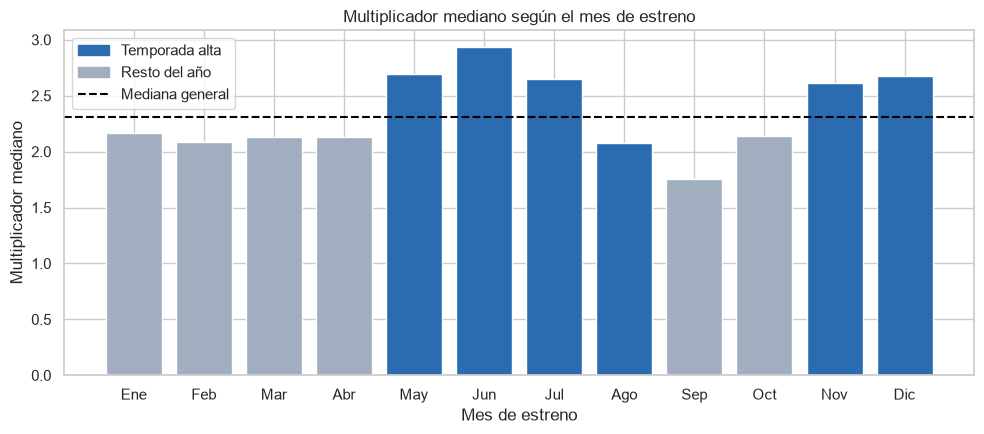

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
temporada,,,,
Resto del año,1540,21.0,2.0,50.6
Temporada alta,1664,31.0,2.6,61.4


In [7]:
assert finanzas["temporada_alta"].eq(finanzas["mes"].isin(MESES_TEMPORADA_ALTA)).all()
finanzas["temporada"] = finanzas["temporada_alta"].map({True: "Temporada alta", False: "Resto del año"})

mediana_por_mes = finanzas.groupby("mes")["multiplicador"].median()
colores = [AZUL if mes in MESES_TEMPORADA_ALTA else GRIS for mes in mediana_por_mes.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar([MESES[mes - 1] for mes in mediana_por_mes.index], mediana_por_mes, color=colores)
ax.axhline(finanzas["multiplicador"].median(), color="black", linestyle="--", linewidth=1.5)
ax.legend(handles=[Patch(color=AZUL, label="Temporada alta"),
                   Patch(color=GRIS, label="Resto del año"),
                   Line2D([], [], color="black", linestyle="--", label="Mediana general")])
ax.set_title("Multiplicador mediano según el mes de estreno")
ax.set_xlabel("Mes de estreno")
ax.set_ylabel("Multiplicador mediano")
plt.tight_layout()
plt.show()

resumir(finanzas, "temporada")

**¿Qué vemos?** Cinco de los seis meses de temporada alta quedan por encima de la mediana general; la excepción es agosto. Junio es el mejor mes y septiembre el peor. En la tabla, las películas de temporada alta tienen un multiplicador mediano de 2,6 contra 2,0 del resto del año, y el 61 % son rentables contra el 51 %.

Pero la tabla también muestra un problema: en temporada alta se estrenan las películas más caras (presupuesto mediano de 31 millones contra 21). Si comparáramos la recaudación, buena parte de la diferencia se explicaría solo por eso. Por eso la prueba usa el multiplicador, que ya está dividido por el presupuesto. Aun así no lo controla todo: en esas fechas también salen las secuelas y las películas con más publicidad.

**Hipótesis 2**

- **H0:** el promedio del logaritmo del multiplicador es igual para las películas estrenadas en temporada alta y para las del resto del año (μ_alta = μ_resto).
- **H1:** el promedio del logaritmo del multiplicador es diferente entre los dos grupos (μ_alta ≠ μ_resto).

**Variables:** `temporada_alta` (cualitativa nominal binaria, derivada del mes de estreno en el notebook 02) y `log10(multiplicador)` (cuantitativa continua).

**Prueba prevista:** t de Student para dos muestras independientes, en la versión de Welch, que no asume que los dos grupos tienen la misma varianza. La t de Student está en la guía de la semana 6; la versión de Welch no, así que la consultamos aparte. Usamos el logaritmo porque la t compara promedios y, como dijimos, el multiplicador sin transformar tiene una cola muy larga. Al final devolvemos la diferencia a la escala original para decirla en términos de negocio (cuántas veces más rinde una película en temporada alta). Es bilateral porque la temporada alta también tiene más competencia: hay más estrenos peleándose por las mismas salas, y eso podría bajar el retorno en vez de subirlo.

**Supuestos a verificar:**

- Normalidad aproximada del logaritmo del multiplicador en cada grupo, con histograma y gráfico Q-Q. Como cada grupo tiene más de 1.500 películas, el teorema del límite central nos da margen si no es perfectamente normal.
- Independencia: cada película está en un solo grupo.
- Varianzas de los grupos: las comparamos para justificar el uso de Welch.

**Qué haríamos con el resultado:**

- Si se rechaza H0 y la temporada alta rinde más, vale la pena pelear por esas fechas, aunque conseguirlas cueste más.
- Si se rechaza y rinde menos, la competencia pesa más que el público extra, y estrenar fuera de temporada sería una estrategia válida.
- Si no se rechaza, la fecha por sí sola no cambia el retorno y se puede escoger por otros criterios, como evitar la competencia directa.

**Lo que no va a poder decir:** que mover una película a julio la vuelva más rentable. Los estudios reservan esas fechas para las películas en las que más confían, entonces el grupo de temporada alta ya viene escogido. Además, en TMDB `release_date` suele ser el primer estreno registrado, que puede ser un festival o el estreno en otro país, no necesariamente el estreno comercial en Estados Unidos.

### 1.5 Hipótesis 3: género y rentabilidad

**Pregunta de negocio:** ¿el género de la película influye en que sea rentable?

El género es de las primeras decisiones de un proyecto: define el guion, el reparto y el público. Si unos géneros tienen más probabilidad de ser rentables que otros, eso ayuda a escoger qué producir.

Usamos el **género principal** (el primero que lista TMDB) y no todos los géneros, porque la chi-cuadrado necesita que cada película se cuente una sola vez; con todos los géneros, una película de acción y aventura aparecería en dos filas de la tabla. Los géneros con menos de 50 películas los juntamos en "Otros": con tan pocas, cada película mueve el porcentaje de rentables 2 puntos o más y la comparación no es confiable. Esa agrupación quedó en la columna `genero_agrupado` del notebook 02.

Películas sin género registrado: 1
Géneros agrupados en 'Otros': Family, Documentary, Mystery, Western, Music, History, War, Foreign


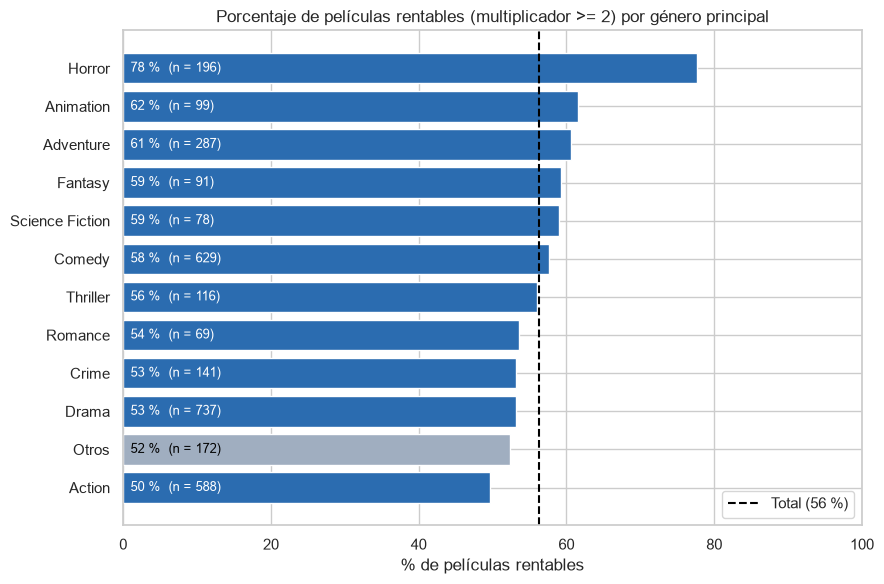

,Películas,Presupuesto mediano (M USD),Multiplicador mediano,% rentables
genero_agrupado,,,,
Horror,196,10.9,3.7,77.6
Animation,99,76.0,2.6,61.6
Adventure,287,60.0,2.7,60.6
Fantasy,91,50.0,2.4,59.3
Science Fiction,78,35.5,2.8,59.0
Comedy,629,20.0,2.5,57.7
Thriller,116,27.0,2.2,56.0
Romance,69,23.0,2.5,53.6
Drama,737,18.0,2.2,53.2


In [8]:
print(f"Películas sin género registrado: {finanzas['genero_agrupado'].isna().sum()}")

con_genero = finanzas.dropna(subset=["genero_agrupado"])
generos_en_otros = con_genero.loc[con_genero["genero_agrupado"] == "Otros", "genero_principal"].value_counts()
print(f"Géneros agrupados en 'Otros': {', '.join(generos_en_otros.index)}")

por_genero = resumir(con_genero, "genero_agrupado").sort_values("% rentables")
porcentaje_total = con_genero["rentable"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
colores = [GRIS if genero == "Otros" else AZUL for genero in por_genero.index]
ax.barh(por_genero.index, por_genero["% rentables"], color=colores)
ax.axvline(porcentaje_total, color="black", linestyle="--", linewidth=1.5,
           label=f"Total ({porcentaje_total:.0f} %)")
barras = zip(por_genero["% rentables"], por_genero["Películas"], colores)
for i, (porcentaje, cantidad, color) in enumerate(barras):
    ax.text(1, i, f"{porcentaje:.0f} %  (n = {cantidad})", va="center", fontsize=9,
            color="white" if color == AZUL else "black")
ax.set_xlim(0, 100)
ax.set_title(f"Porcentaje de películas rentables (multiplicador >= {UMBRAL_RENTABLE}) por género principal")
ax.set_xlabel("% de películas rentables")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

por_genero.sort_values("% rentables", ascending=False)

**¿Qué vemos?** Hay diferencias grandes entre géneros. Terror (*Horror*) es el que más se sale: el 78 % de sus películas son rentables, contra el 56 % del total. En el otro extremo está acción (*Action*), con menos de la mitad. La mayoría de géneros queda entre 53 % y 62 %, cerca del total.

La tabla deja ver algo que hay que tener en cuenta: terror tiene el presupuesto mediano más bajo de los géneros grandes (11 millones, contra 44 de acción). Eso lo conecta con la hipótesis 1, porque puede que no sea el género sino el presupuesto lo que hace la diferencia, o las dos cosas. La chi-cuadrado no separa esos dos efectos, así que hay que tenerlo presente al interpretar.

**Hipótesis 3**

- **H0:** el género principal y ser rentable son independientes, es decir, la proporción de películas rentables es la misma en todos los géneros.
- **H1:** el género principal y ser rentable están asociados: al menos un género tiene una proporción de rentables distinta.

**Variables:** `genero_agrupado` (cualitativa nominal: el género principal, con los de menos de 50 películas en "Otros") y `rentable` (cualitativa nominal binaria, derivada del multiplicador).

**Prueba prevista:** chi-cuadrado de independencia sobre la tabla de contingencia género × rentable (12 × 2), que es la prueba de la guía de la semana 6 para dos variables categóricas. La chi-cuadrado no tiene dirección: si sale significativa, solo dice que hay asociación y no cuáles géneros la producen, así que después comparamos las frecuencias observadas con las esperadas para ver qué géneros se alejan más. Para medir qué tan fuerte es la asociación pensamos usar la V de Cramér, que no está en las guías y la tendríamos que consultar aparte.

**Supuestos a verificar:**

- Frecuencias esperadas mayores que 5 en todas las celdas. El grupo más pequeño tiene 69 películas y un 44 % de no rentables en total, así que la esperada más baja debería quedar alrededor de 30; no esperamos problemas, pero hay que confirmarlo.
- Independencia: cada película se cuenta una sola vez, que es la razón para usar el género principal.

**Qué haríamos con el resultado:**

- Si se rechaza H0, el género sí pesa en la probabilidad de recuperar la inversión, y la productora puede darles prioridad a los géneros que queden por encima de lo esperado, mirando también el presupuesto típico de cada uno.
- Si no se rechaza, no hay evidencia de que algún género sea más seguro que otro, y el género se puede escoger por otros criterios (público objetivo, costo, talento disponible).

**Lo que no va a poder decir:** que hacer una película de terror garantice que sea rentable, ni que el género sea la causa. Además, el primer género de TMDB no siempre es el que mejor describe la película: una comedia romántica puede aparecer primero como *Romance* o como *Comedy*.

### 1.6 Resumen de las hipótesis

| | Pregunta de negocio | Variables | Prueba prevista | Supuesto más delicado |
|---|---|---|---|---|
| **H1** | ¿Más presupuesto rinde más por dólar? | `budget`, `multiplicador` | Correlación de Spearman (toda la base y desde 2000) | Montos bien limpios y control por época |
| **H2** | ¿Estrenar en temporada alta rinde más? | `temporada_alta`, `log10(multiplicador)` | t de Student para muestras independientes (Welch) | Normalidad aproximada del logaritmo |
| **H3** | ¿El género influye en que una película sea rentable? | `genero_agrupado`, `rentable` | Chi-cuadrado de independencia | Frecuencias esperadas mayores que 5 |

Y lo que le costaría a la productora equivocarse en cada caso:

| | Error tipo I (rechazar H0 siendo cierta) | Error tipo II (no rechazar H0 siendo falsa) |
|---|---|---|
| **H1** | Recorta presupuestos creyendo que así rinden más, y pierde alcance sin ganar retorno. | Sigue invirtiendo igual sin aprovechar una diferencia real de rendimiento. |
| **H2** | Paga más por fechas de temporada alta que en realidad no mejoran el retorno. | Estrena en cualquier fecha y desaprovecha una temporada que sí rinde más. |
| **H3** | Se casa con un género que en realidad no es más seguro que los demás. | Ignora un género con más probabilidad de ser rentable. |

Las tres hipótesis comparten las mismas limitaciones de base: solo cubren las películas que reportaron presupuesto y recaudación, ninguna prueba demuestra causalidad y la definición de rentable es una aproximación. Las pruebas las corremos en la siguiente parte de este notebook.

## 2. Validación de las hipótesis

En esta parte corremos las pruebas que dejamos planteadas. Para cada hipótesis seguimos el mismo orden: verificamos los supuestos, corremos la prueba con α = 0,05, tomamos la decisión con el valor p y después miramos qué tan grande es el efecto y qué significa para la productora, como lo acordamos en la sección 1.2.

### 2.1 Prueba de la hipótesis 1: presupuesto y multiplicador

Lo que vamos a probar:

- **H0:** no hay correlación entre el presupuesto y el multiplicador (ρ = 0).
- **H1:** sí hay correlación entre el presupuesto y el multiplicador (ρ ≠ 0).

Como lo decidimos en la sección 1.3, corremos la prueba dos veces: sobre toda la base financiera y solo con las películas estrenadas desde 2000, donde los presupuestos están en dólares de años parecidos y el sesgo de los clásicos pesa mucho menos.

#### Supuestos

La correlación de Spearman no exige que los datos tengan distribución normal, porque trabaja con los rangos (la posición de cada película al ordenarlas) y no con los valores. Lo que sí necesita es que las observaciones sean independientes y que, si hay relación, sea monótona: que cuando una variable sube, la otra tienda siempre a subir o siempre a bajar. Revisamos esos dos puntos y la limpieza de los montos.

In [9]:
import numpy as np
from scipy import stats

ALFA = 0.05
ANIO_CORTE = 2000

desde_2000 = finanzas[finanzas["anio"] >= ANIO_CORTE]
poblaciones_h1 = {"Toda la base": finanzas, f"Desde {ANIO_CORTE}": desde_2000}

assert finanzas["id"].is_unique, "Hay películas repetidas en la base financiera"
print(f"Películas en toda la base: {len(finanzas):,}")
print(f"Películas desde {ANIO_CORTE}: {len(desde_2000):,}")
print(f"Presupuesto mínimo de la base: {finanzas['budget'].min():,.0f} USD")
print(f"Asimetría del presupuesto: {stats.skew(finanzas['budget']):.1f}")
print(f"Asimetría del multiplicador: {stats.skew(finanzas['multiplicador']):.1f}")

Películas en toda la base: 3,204
Películas desde 2000: 2,265
Presupuesto mínimo de la base: 10,000 USD
Asimetría del presupuesto: 2.1
Asimetría del multiplicador: 49.7


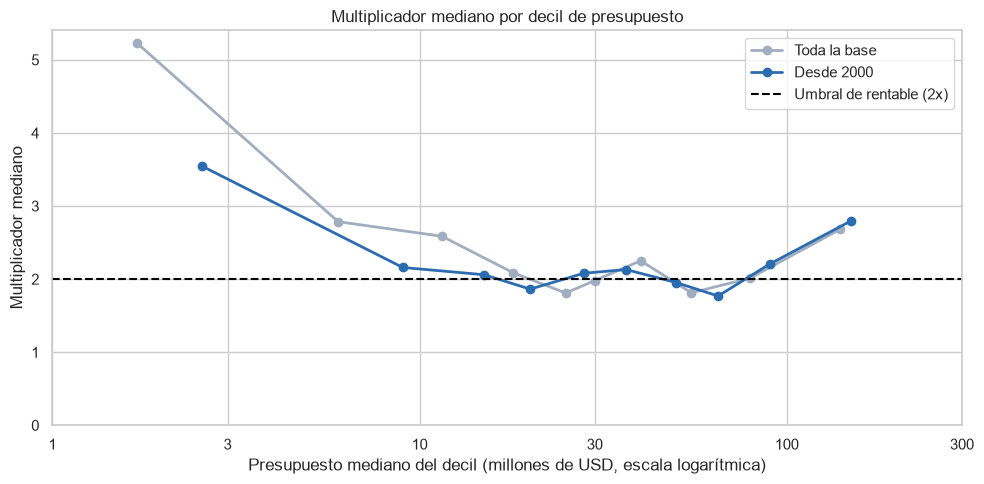

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
for (nombre, datos), color in zip(poblaciones_h1.items(), [GRIS, AZUL]):
    decil = pd.qcut(datos["budget"], 10)
    por_decil = datos.groupby(decil, observed=True).agg(presupuesto=("budget", "median"),
                                                        multiplicador=("multiplicador", "median"))
    ax.plot(por_decil["presupuesto"], por_decil["multiplicador"], marker="o", linewidth=2,
            color=color, label=nombre)
ax.axhline(UMBRAL_RENTABLE, color="black", linestyle="--", linewidth=1.5,
           label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
ax.set_xscale("log")
ax.set_xticks([1e6, 3e6, 1e7, 3e7, 1e8, 3e8])
ax.xaxis.set_major_formatter(FORMATO_MILLONES)
ax.set_ylim(0, None)
ax.set_title("Multiplicador mediano por decil de presupuesto")
ax.set_xlabel("Presupuesto mediano del decil (millones de USD, escala logarítmica)")
ax.set_ylabel("Multiplicador mediano")
ax.legend()
plt.tight_layout()
plt.show()

**¿Qué vemos?**

- **Independencia:** cada película aparece una sola vez en la base, así que la tomamos como una observación independiente. Hay una dependencia que no podemos controlar con estos datos: las películas que se estrenan la misma semana compiten por el mismo público.
- **Montos limpios:** el presupuesto más bajo de la base es de 10.000 dólares, porque los montos dudosos quedaron por fuera en la limpieza (notebook 02, sección 2.4). Más abajo lo revisamos otra vez con un corte más exigente.
- **Por qué Spearman y no Pearson:** la asimetría del multiplicador es de 49,7, muy lejos del 0 de una distribución simétrica (medidas de forma, guía de la semana 4). Con una cola así, unas pocas películas dominarían una correlación de Pearson. Spearman usa los rangos: para él, una película que recaudó 1.000 veces su presupuesto solo cuenta como el puesto más alto, sin importar qué tan lejos esté de las demás.
- **Monotonía:** en toda la base (gris) el multiplicador mediano baja con fuerza en los primeros deciles, de 5,2 en el más barato a cerca de 2, se queda plano y sube un poco en los dos deciles más caros. La bajada inicial pesa mucho más que la subida final, así que predomina una tendencia descendente que Spearman sí puede medir. Desde 2000 (azul) la curva es casi plana alrededor de 2, con los dos extremos un poco más arriba: 3,6 en el decil más barato y 2,8 en el más caro. Esa forma de U no es monótona y Spearman no la capta bien. Lo tenemos en cuenta al interpretar: si la prueba desde 2000 sale sin correlación, eso no quiere decir que el presupuesto no tenga ningún efecto, sino que no hay una tendencia en una sola dirección.

#### Prueba de correlación de Spearman

Para cada población calculamos el coeficiente ρ de Spearman y su valor p con `scipy.stats.spearmanr`. Para entender de dónde sale el valor p, también calculamos el estadístico de la guía de la semana 4, t = ρ·√((n − 2) / (1 − ρ²)), que sigue una distribución t con n − 2 grados de libertad. La guía lo plantea para Pearson; con Spearman se usa la misma fórmula, pero con el coeficiente calculado sobre los rangos. Es lo que hace `scipy` por dentro, así que verificamos que los dos valores p coincidan.

Agregamos una columna más, el **ρ mínimo detectable**: el valor más pequeño de ρ que, con ese número de películas, ya saldría significativo con α = 0,05. Sale de despejar ρ en la misma fórmula y nos dice si la muestra alcanza para ver una correlación pequeña.

In [11]:
def rho_minimo(n, alfa=ALFA):
    # Despeja ρ en t = ρ·√((n − 2) / (1 − ρ²)) usando el t crítico bilateral
    t_critico = stats.t.ppf(1 - alfa / 2, n - 2)
    return t_critico / np.sqrt(n - 2 + t_critico**2)


def probar_spearman(datos):
    n = len(datos)
    resultado = stats.spearmanr(datos["budget"], datos["multiplicador"])
    rho, valor_p = resultado.statistic, resultado.pvalue
    t = rho * np.sqrt((n - 2) / (1 - rho**2))
    assert np.isclose(2 * stats.t.sf(abs(t), n - 2), valor_p), "El valor p no coincide con la fórmula"
    return {
        "Películas": n,
        "Presupuesto mediano (M USD)": round(datos["budget"].median() / 1e6, 1),
        "ρ de Spearman": round(rho, 4),
        "t": round(t, 2),
        "Valor p": f"{valor_p:.1e}" if valor_p < 0.001 else f"{valor_p:.3f}",
        "ρ mínimo detectable": round(rho_minimo(n), 3),
        "Decisión": "Se rechaza H0" if valor_p < ALFA else "No se rechaza H0",
    }


resultados_h1 = pd.DataFrame({nombre: probar_spearman(datos)
                              for nombre, datos in poblaciones_h1.items()}).T
resultados_h1.rename_axis("Población")

,Películas,Presupuesto mediano (M USD),ρ de Spearman,t,Valor p,ρ mínimo detectable,Decisión
Población,,,,,,,
Toda la base,3204,25.5,-0.1368,-7.81,7.5e-15,0.035,Se rechaza H0
Desde 2000,2265,30.0,-0.0001,-0.01,0.996,0.041,No se rechaza H0


**¿Qué vemos?** Las dos pruebas dan resultados opuestos:

- **Toda la base:** ρ = −0,137 y valor p de 7,5 × 10⁻¹⁵, muy por debajo de 0,05. **Se rechaza H0**: hay evidencia de una correlación negativa entre presupuesto y multiplicador. En general, las películas más caras recuperan menos veces lo que costaron.
- **Desde 2000:** ρ = −0,0001 y valor p de 0,996. **No se rechaza H0**: no hay evidencia de correlación entre presupuesto y multiplicador en las películas recientes. El ρ no solo no es significativo, es prácticamente cero.

Incluso en toda la base la correlación es débil: −0,137 está mucho más cerca de 0 que de −1. Con 3.204 películas cualquier ρ por encima de 0,035 sale significativo, que es justo lo que advertimos en la sección 1.2: el valor p solo no basta.

El ρ mínimo detectable también descarta que el segundo resultado sea por falta de datos: con 2.265 películas, una correlación de ±0,041 ya habría salido significativa. Si en el cine reciente existe alguna correlación monótona entre presupuesto y multiplicador, es tan pequeña que no le serviría a la productora para decidir cuánto invertir. Aun así, no decimos que «se acepta» H0: concluimos que los datos no muestran evidencia de una relación.

Queda la pregunta de por qué la correlación desaparece al quitar las películas anteriores a 2000.

#### ¿De dónde sale la correlación? Control por época y por montos

Para ubicar de dónde viene la correlación de toda la base, repetimos la prueba por periodos. También revisamos el supuesto de los montos limpios: si la correlación negativa la estuvieran creando presupuestos mal digitados que pasaron el filtro de 10.000 dólares, debería debilitarse mucho al quitar las películas con presupuesto menor a 1 millón de dólares. Ese corte de 1 millón es solo una prueba de sensibilidad; no cambia la base financiera.

In [12]:
subgrupos = {
    f"Antes de {ANIO_CORTE}": finanzas[finanzas["anio"] < ANIO_CORTE],
    "2000-2009": finanzas[finanzas["anio"].between(2000, 2009)],
    "2010-2017": finanzas[finanzas["anio"] >= 2010],
    "Toda la base, presupuesto >= 1 M": finanzas[finanzas["budget"] >= 1e6],
    f"Desde {ANIO_CORTE}, presupuesto >= 1 M": desde_2000[desde_2000["budget"] >= 1e6],
}

pd.DataFrame({nombre: probar_spearman(datos) for nombre, datos in subgrupos.items()}).T.rename_axis("Subgrupo")

,Películas,Presupuesto mediano (M USD),ρ de Spearman,t,Valor p,ρ mínimo detectable,Decisión
Subgrupo,,,,,,,
Antes de 2000,939,16.0,-0.35,-11.44,1.9e-28,0.064,Se rechaza H0
2000-2009,1324,30.0,-0.0207,-0.75,0.453,0.054,No se rechaza H0
2010-2017,941,30.0,0.0163,0.5,0.618,0.064,No se rechaza H0
"Toda la base, presupuesto >= 1 M",3105,27.5,-0.0996,-5.58,2.7e-08,0.035,Se rechaza H0
"Desde 2000, presupuesto >= 1 M",2216,30.0,0.0177,0.83,0.405,0.042,No se rechaza H0


**¿Qué vemos?** La correlación negativa sale casi entera de las películas anteriores a 2000: ahí ρ = −0,350, más del doble que en toda la base, con un valor p de 1,9 × 10⁻²⁸. En 2000-2009 y en 2010-2017, cada década por separado, ρ queda pegado a cero y no se rechaza H0.

Es lo que sospechamos en la sección 1.3. Antes de 2000 los presupuestos están en dólares de otra época (mediana de 16 millones, contra 30 desde 2000), y las películas viejas que tienen cifras en TMDB son sobre todo clásicos que funcionaron. Al mezclar las dos épocas, las películas viejas quedan en el extremo barato con multiplicadores altos, y eso fabrica en toda la base una correlación negativa que no aparece dentro de ninguna década reciente.

Quitar los presupuestos menores a 1 millón casi no cambia nada: en toda la base ρ pasa de −0,137 a −0,100 y sigue siendo significativo, y desde 2000 sigue sin serlo. El resultado no depende de unos pocos montos raros que se le escaparon a la limpieza; lo que manda es la época.

#### Magnitud: ¿qué cambia con el presupuesto en el cine reciente?

Que el multiplicador no tenga correlación con el presupuesto no quiere decir que dé lo mismo invertir 5 que 100 millones. Para verlo en términos de negocio, partimos las películas desde 2000 en cuartiles de presupuesto y miramos toda la distribución del multiplicador, no solo la mediana: su cuartil 1 y su cuartil 3 (entre esos dos valores está la mitad central de las películas) y el porcentaje que **perdió plata**, es decir, que recaudó menos de lo que costó (multiplicador menor a 1). También medimos la correlación entre presupuesto y recaudación, para comparar.

Presupuesto vs. recaudación (toda la base): ρ = 0.67, valor p < 0.001
Presupuesto vs. recaudación (desde 2000): ρ = 0.72, valor p < 0.001


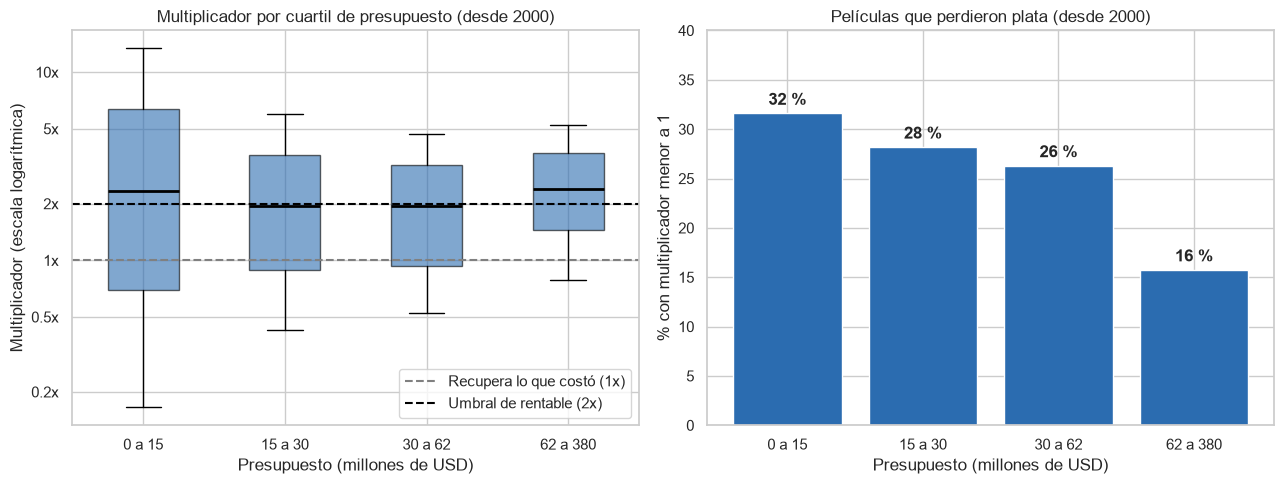

,Películas,Multiplicador Q1,Multiplicador mediano,Multiplicador Q3,% perdieron plata,% rentables
Presupuesto (M USD),,,,,,
0 a 15,639,0.7,2.3,6.4,31.6,55.1
15 a 30,525,0.9,1.9,3.6,28.2,48.4
30 a 62,536,0.9,2.0,3.2,26.3,48.5
62 a 380,565,1.4,2.4,3.7,15.8,60.2


In [13]:
for nombre, datos in poblaciones_h1.items():
    resultado = stats.spearmanr(datos["budget"], datos["revenue"])
    valor_p = "< 0.001" if resultado.pvalue < 0.001 else f"= {resultado.pvalue:.3f}"
    print(f"Presupuesto vs. recaudación ({nombre.lower()}): ρ = {resultado.statistic:.2f}, valor p {valor_p}")

cortes = desde_2000["budget"].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
etiquetas = [f"{inicio / 1e6:.0f} a {fin / 1e6:.0f}" for inicio, fin in zip(cortes[:-1], cortes[1:])]
cuartil = pd.cut(desde_2000["budget"], cortes, labels=etiquetas, include_lowest=True)

riesgo = desde_2000.groupby(cuartil, observed=True).agg(
    peliculas=("multiplicador", "size"),
    multiplicador_q1=("multiplicador", lambda m: m.quantile(0.25)),
    multiplicador_mediano=("multiplicador", "median"),
    multiplicador_q3=("multiplicador", lambda m: m.quantile(0.75)),
    perdieron=("multiplicador", lambda m: (m < 1).mean() * 100),
    rentables=("rentable", "mean"),
)
riesgo["rentables"] *= 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

grupos = [desde_2000.loc[cuartil == etiqueta, "multiplicador"] for etiqueta in etiquetas]
ax1.boxplot(grupos, whis=(10, 90), showfliers=False, widths=0.5, patch_artist=True,
            boxprops={"facecolor": AZUL, "alpha": 0.6}, medianprops={"color": "black", "linewidth": 2})
ax1.set_xticks(range(1, len(etiquetas) + 1), etiquetas)
ax1.axhline(1, color="gray", linestyle="--", linewidth=1.5, label="Recupera lo que costó (1x)")
ax1.axhline(UMBRAL_RENTABLE, color="black", linestyle="--", linewidth=1.5,
            label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
ax1.set_yscale("log")
ax1.set_yticks([0.2, 0.5, 1, 2, 5, 10])
ax1.minorticks_off()
ax1.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}x"))
ax1.set_title(f"Multiplicador por cuartil de presupuesto (desde {ANIO_CORTE})")
ax1.set_xlabel("Presupuesto (millones de USD)")
ax1.set_ylabel("Multiplicador (escala logarítmica)")
ax1.legend(loc="lower right")

ax2.bar(etiquetas, riesgo["perdieron"], color=AZUL)
for i, valor in enumerate(riesgo["perdieron"]):
    ax2.text(i, valor + 0.5, f"{valor:.0f} %", ha="center", va="bottom", fontweight="bold")
ax2.set_ylim(0, 40)
ax2.set_title(f"Películas que perdieron plata (desde {ANIO_CORTE})")
ax2.set_xlabel("Presupuesto (millones de USD)")
ax2.set_ylabel("% con multiplicador menor a 1")

plt.tight_layout()
plt.show()

riesgo.round(1).rename_axis("Presupuesto (M USD)").rename(columns={
    "peliculas": "Películas",
    "multiplicador_q1": "Multiplicador Q1",
    "multiplicador_mediano": "Multiplicador mediano",
    "multiplicador_q3": "Multiplicador Q3",
    "perdieron": "% perdieron plata",
    "rentables": "% rentables",
})

**¿Qué vemos?** En el gráfico de la izquierda cada caja va del cuartil 1 al cuartil 3 del multiplicador y los bigotes van del percentil 10 al 90; no dibujamos las películas más extremas para que se puedan comparar las cajas.

- **La recaudación sí depende del presupuesto.** Entre presupuesto y recaudación ρ = 0,72 desde 2000: más plata trae más taquilla, como era de esperarse. Pero como el multiplicador no cambia, la recaudación crece más o menos al mismo ritmo que el presupuesto. En la mediana, una película el doble de cara recauda cerca del doble, no más.
- **El retorno típico es casi igual en todos los cuartiles.** El multiplicador mediano va de 1,9 a 2,4. El cuartil más caro queda un poco arriba (2,4 y 60 % de rentables), pero la diferencia es pequeña y, como vimos en la prueba, no forma una tendencia.
- **Lo que sí cambia es el riesgo.** En el cuartil más barato (hasta 15 millones) el 32 % de las películas perdió plata, y la mitad central va de 0,7 a 6,4 veces el presupuesto: hay de todo, desde fracasos totales hasta éxitos enormes. En el cuartil más caro (más de 62 millones) solo el 16 % perdió plata, y la mitad central va de 1,4 a 3,7. Las películas grandes rinden parecido, pero son mucho más predecibles.

Esta comparación del riesgo es descriptiva: no la sometimos a una prueba de hipótesis, porque no era lo que planteaba la H1. Además, el sesgo de selección que mencionamos en la sección 1.3 va en la misma dirección: una película pequeña que fracasó tiene menos probabilidad de reportar su taquilla, así que el riesgo real de las películas baratas probablemente es todavía mayor que el que vemos aquí.

#### Conclusión de la hipótesis 1

| Población | Películas | ρ de Spearman | Valor p | Decisión |
|---|---|---|---|---|
| Toda la base | 3.204 | −0,137 | 7,5 × 10⁻¹⁵ | Se rechaza H0 |
| Desde 2000 | 2.265 | −0,0001 | 0,996 | No se rechaza H0 |

**Respuesta a la pregunta de negocio: ¿cuánto invertir?** La correlación negativa de toda la base no es un argumento para hacer películas baratas, porque viene de mezclar épocas. En el cine reciente, que es la referencia que le sirve a una productora hoy, no encontramos evidencia de que más presupuesto rinda más ni menos por cada dólar invertido. Es el tercer escenario que planteamos en la sección 1.3: el presupuesto por sí solo no dice cuánto va a rendir la película, y esa decisión se tiene que apoyar también en la fecha de estreno y en el género (hipótesis 2 y 3).

Lo que el presupuesto sí cambia es qué tan incierto es el resultado. Para una productora con capital limitado eso pesa: si su capital solo le alcanza para películas de bajo presupuesto, cada una es una apuesta con cerca de un tercio de probabilidad de perder plata. Por eso tiene más sentido repartir el capital en varias producciones pequeñas que apostarlo todo a una sola. Esta recomendación sale de la comparación descriptiva del riesgo, no de la prueba.

**Lo que no podemos concluir:**

- No es una relación de causa y efecto. Aunque hubiéramos encontrado correlación, no probaría que cambiar el presupuesto cambie el retorno.
- Spearman solo mide tendencias en una dirección. La forma de U que vimos desde 2000 (los extremos un poco más arriba) no la captura, y con esta prueba no sabemos si es real o ruido.
- Los montos están en dólares nominales. Trabajando desde 2000 la distorsión es menor, pero no desaparece del todo.
- La base solo tiene películas que reportaron cifras, que tienden a ser las más comerciales.
- Como desde 2000 no rechazamos H0, podríamos estar cometiendo un error tipo II. Pero el ρ mínimo detectable (0,041) indica que, si hay una correlación que no vimos, es demasiado pequeña para cambiar una decisión de inversión.

**Para las siguientes pruebas:** el control por época cambió por completo la conclusión de esta hipótesis, así que vale la pena revisar si las hipótesis 2 y 3 se mantienen con las películas desde 2000.

### 2.2 Prueba de la hipótesis 2: temporada de estreno

Lo que vamos a probar:

- **H0:** el promedio del logaritmo del multiplicador es igual para las películas estrenadas en temporada alta y para las del resto del año (μ_alta = μ_resto).
- **H1:** el promedio del logaritmo del multiplicador es diferente entre los dos grupos (μ_alta ≠ μ_resto).

La temporada alta es la misma de la sección 1.4: películas estrenadas de mayo a agosto o en noviembre y diciembre. Como quedó planteado, trabajamos con `log10(multiplicador)` y con la t de Student en su versión de Welch. Y como en la hipótesis 1 todo cambió cuando quitamos las películas viejas, aquí hacemos lo mismo: corremos la prueba con toda la base financiera y después solo con las películas desde 2000.

#### Supuestos

Para usar la t de Student hay que revisar tres cosas: que en cada grupo la variable sea más o menos normal, que las observaciones sean independientes y, si se usa la versión clásica, que los dos grupos tengan la misma varianza. La normalidad la miramos con un histograma, con la asimetría y la curtosis (guía de la semana 4) y con un gráfico Q-Q. Para el Q-Q estandarizamos el logaritmo (guía de la semana 5) y lo comparamos con los cuantiles de una normal: si los datos fueran normales, los puntos quedarían encima de la línea punteada.

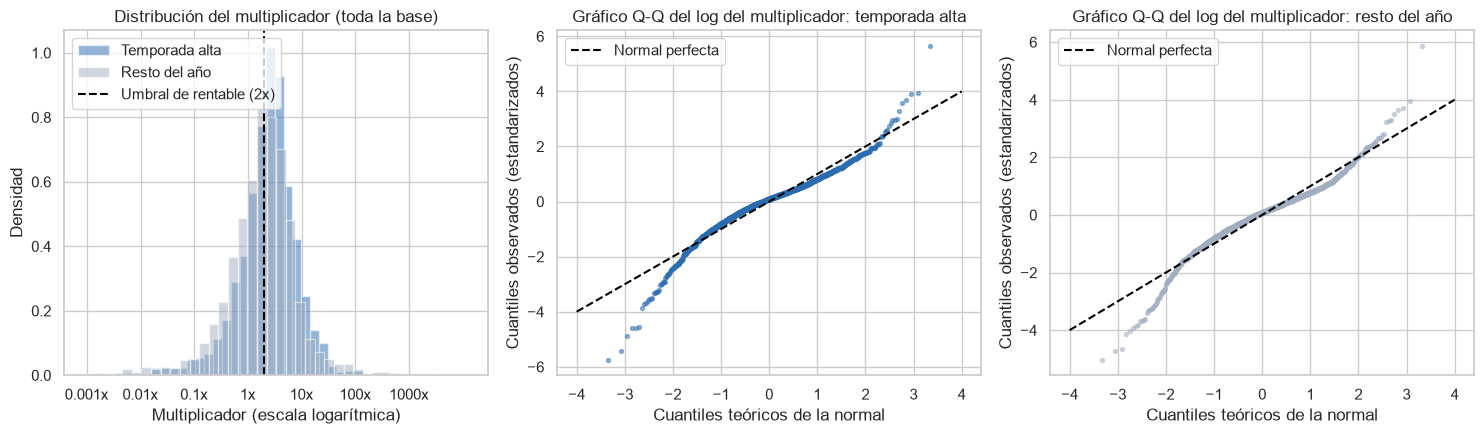

Películas  Asimetría del multiplicador  \
Población    Temporada                                                
Toda la base Temporada alta       1664                         38.6   
             Resto del año        1540                         38.7   
Desde 2000   Temporada alta       1092                         21.0   
             Resto del año        1173                         34.1   

                             Asimetría del log  Curtosis del log  \
Población    Temporada                                             
Toda la base Temporada alta              -0.71              3.93   
             Resto del año               -0.49              3.59   
Desde 2000   Temporada alta              -1.25              4.72   
             Resto del año               -0.73              4.78   

                             Promedio del log  Desviación estándar del log  
Población    Temporada                                                      
Toda la base Temporada alta             0.363                        0.577  
             Resto del año              0.250                        0.659  
Desde 2000   Temporada alta             0.290                        0.551  
             Resto del año              0.225                        0.610

In [14]:
TEMPORADAS = ["Temporada alta", "Resto del año"]
COLORES_TEMPORADA = {"Temporada alta": AZUL, "Resto del año": GRIS}
CONFIANZA = 0.95

poblaciones_h2 = {"Toda la base": finanzas, f"Desde {ANIO_CORTE}": desde_2000}


def separar_temporadas(datos):
    log_multiplicador = np.log10(datos["multiplicador"])
    return {temporada: log_multiplicador[datos["temporada"] == temporada] for temporada in TEMPORADAS}


forma = {}
for nombre, datos in poblaciones_h2.items():
    for temporada, valores in separar_temporadas(datos).items():
        multiplicador = datos.loc[datos["temporada"] == temporada, "multiplicador"]
        forma[(nombre, temporada)] = {
            "Películas": len(valores),
            "Asimetría del multiplicador": round(stats.skew(multiplicador), 1),
            "Asimetría del log": round(stats.skew(valores), 2),
            "Curtosis del log": round(stats.kurtosis(valores), 2),
            "Promedio del log": round(valores.mean(), 3),
            "Desviación estándar del log": round(valores.std(), 3),
        }

grupos = separar_temporadas(finanzas)
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))

marcas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
for temporada, valores in grupos.items():
    ejes[0].hist(valores, bins=40, density=True, alpha=0.5, color=COLORES_TEMPORADA[temporada],
                 label=temporada)
ejes[0].axvline(np.log10(UMBRAL_RENTABLE), color="black", linestyle="--", linewidth=1.5,
                label=f"Umbral de rentable ({UMBRAL_RENTABLE}x)")
ejes[0].set_xticks(np.log10(marcas), [f"{marca:g}x" for marca in marcas])
ejes[0].set_title("Distribución del multiplicador (toda la base)")
ejes[0].set_xlabel("Multiplicador (escala logarítmica)")
ejes[0].set_ylabel("Densidad")
ejes[0].legend(loc="upper left")

for ax, (temporada, valores) in zip(ejes[1:], grupos.items()):
    estandarizados = (valores - valores.mean()) / valores.std()
    teoricos, observados = stats.probplot(estandarizados, dist="norm", fit=False)
    ax.scatter(teoricos, observados, s=8, alpha=0.5, color=COLORES_TEMPORADA[temporada])
    ax.plot([-4, 4], [-4, 4], color="black", linestyle="--", linewidth=1.5, label="Normal perfecta")
    ax.set_title(f"Gráfico Q-Q del log del multiplicador: {temporada.lower()}")
    ax.set_xlabel("Cuantiles teóricos de la normal")
    ax.set_ylabel("Cuantiles observados (estandarizados)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

pd.DataFrame.from_dict(forma, orient="index").rename_axis(["Población", "Temporada"])

**¿Qué vemos?**

El logaritmo hizo su trabajo. Sin transformar, el multiplicador tiene una asimetría entre 21,0 y 38,7 según el grupo, por unas pocas películas que recaudaron cientos y hasta miles de veces lo que costaron. Con el logaritmo la asimetría queda entre −0,49 y −1,25, ya cerca de 0, y en el histograma los dos grupos quedan con forma de campana alrededor del 2x.

Eso sí, no es una normal perfecta. La asimetría que queda es negativa porque ahora la cola está a la izquierda: son las películas que recaudaron muy poquito comparado con lo que costaron. La curtosis da entre 3,59 y 4,78, y como `scipy` la calcula para que una normal dé 0, eso quiere decir que hay más películas en los extremos de las que habría en una normal. En los Q-Q se ve igual: en el centro los puntos van pegados a la línea y en las puntas se abren, sobre todo abajo a la izquierda, donde están los fracasos.

Aun así la t nos sirve, porque no compara películas sueltas sino promedios. Cada grupo tiene más de 1.000 películas (el más pequeño, desde 2000, tiene 1.092), y con tantas el teorema del límite central hace que el promedio se comporte casi como una normal aunque los datos no lo sean. Lo que sí hay que tener presente es que, con colas tan pesadas, unas pocas películas extremas mueven el promedio, y por eso más abajo también miramos la mediana y los cuartiles.

Con las varianzas toca tener cuidado. La desviación estándar del logaritmo es 0,577 en temporada alta y 0,659 en el resto del año, o sea que la varianza del resto es más o menos un 30 % mayor (desde 2000 es 0,551 contra 0,610, un 23 % mayor). Los resultados de las películas que salen fuera de temporada están más regados, y más abajo vemos que buena parte de eso son películas que pierden plata. Por eso usamos Welch, que no pide que las varianzas sean iguales.

Sobre la independencia, cada película queda en un solo grupo porque tiene un solo mes de estreno. Pasa lo mismo que dijimos en la hipótesis 1: las películas que se estrenan la misma semana se pelean el mismo público, y eso no lo podemos controlar con estos datos.

#### Prueba t de Welch

La t de Welch se parece a la t de Student para dos muestras. La diferencia es que cada grupo pone su propia varianza en el error estándar:

t = (x̄_alta − x̄_resto) / √(s²_alta / n_alta + s²_resto / n_resto)

Los grados de libertad tampoco son n_alta + n_resto − 2. Se sacan con la fórmula de Welch-Satterthwaite, que da menos grados de libertad cuando las varianzas no son iguales. Como ninguna de las dos fórmulas está en las guías, las calculamos nosotros en el código y revisamos que den lo mismo que `scipy.stats.ttest_ind(..., equal_var=False)`. También sacamos el intervalo de confianza del 95 % de la diferencia de promedios (guía de la semana 6) y, para comparar, corrimos la t de Student clásica, la que supone varianzas iguales.

Para que el resultado se entienda sin logaritmos hay que devolverlo a la escala normal. Como el logaritmo es en base 10, eso es 10 elevado a la diferencia de promedios, y lo mismo con los dos extremos del intervalo. Ese número dice cuántas veces es el multiplicador típico de una película de temporada alta comparado con el de una del resto del año. Si diera 1x, no habría diferencia.

In [15]:
def formatear_p(valor_p):
    return f"{valor_p:.1e}" if valor_p < 0.001 else f"{valor_p:.3f}"


def probar_welch(datos):
    alta, resto = separar_temporadas(datos).values()
    resultado = stats.ttest_ind(alta, resto, equal_var=False)
    var_alta, var_resto = alta.var() / len(alta), resto.var() / len(resto)
    diferencia = alta.mean() - resto.mean()
    t = diferencia / np.sqrt(var_alta + var_resto)
    gl = (var_alta + var_resto) ** 2 / (var_alta**2 / (len(alta) - 1) + var_resto**2 / (len(resto) - 1))
    assert np.isclose(t, resultado.statistic), "El t no coincide con la fórmula"
    assert np.isclose(gl, resultado.df), "Los grados de libertad no coinciden con la fórmula"
    intervalo = resultado.confidence_interval(CONFIANZA)
    return {"n_alta": len(alta), "n_resto": len(resto), "diferencia": diferencia, "t": t, "gl": gl,
            "valor_p": resultado.pvalue, "ic_bajo": intervalo.low, "ic_alto": intervalo.high}


def tabla_welch(poblaciones):
    filas = {}
    for nombre, datos in poblaciones.items():
        prueba = probar_welch(datos)
        filas[nombre] = {
            "Temporada alta": prueba["n_alta"],
            "Resto del año": prueba["n_resto"],
            "Diferencia del log": round(prueba["diferencia"], 3),
            "t de Welch": round(prueba["t"], 2),
            "Grados de libertad": round(prueba["gl"], 1),
            "Valor p": formatear_p(prueba["valor_p"]),
            "Decisión": "Se rechaza H0" if prueba["valor_p"] < ALFA else "No se rechaza H0",
            "Rinde en temporada alta": f"{10 ** prueba['diferencia']:.2f}x",
            f"IC {CONFIANZA * 100:.0f} %": f"{10 ** prueba['ic_bajo']:.2f}x a {10 ** prueba['ic_alto']:.2f}x",
        }
    return pd.DataFrame.from_dict(filas, orient="index").rename_axis("Población")


for nombre, datos in poblaciones_h2.items():
    alta, resto = separar_temporadas(datos).values()
    clasica = stats.ttest_ind(alta, resto)
    print(f"t de Student clásica ({nombre.lower()}): t = {clasica.statistic:.2f}, "
          f"valor p = {formatear_p(clasica.pvalue)}")

tabla_welch(poblaciones_h2)

t de Student clásica (toda la base): t = 5.18, valor p = 2.4e-07
t de Student clásica (desde 2000): t = 2.65, valor p = 0.008


,Temporada alta,Resto del año,Diferencia del log,t de Welch,Grados de libertad,Valor p,Decisión,Rinde en temporada alta,IC 95 %
Población,,,,,,,,,
Toda la base,1664,1540,0.113,5.15,3067.6,2.8e-07,Se rechaza H0,1.30x,1.17x a 1.43x
Desde 2000,1092,1173,0.065,2.66,2261.0,0.008,Se rechaza H0,1.16x,1.04x a 1.30x


**¿Qué vemos?** Se rechaza H0 en las dos poblaciones.

En toda la base la diferencia de promedios del logaritmo es 0,113, con t = 5,15 y un valor p de 2,8 × 10⁻⁷. Pasado a veces, el multiplicador típico de la temporada alta es 1,30 veces el del resto del año, y el intervalo de confianza va de 1,17 a 1,43, así que no toca el 1.

Desde 2000 la diferencia baja a 0,065, con t = 2,66 y un valor p de 0,008. En veces da 1,16, con un intervalo de 1,04 a 1,30 que tampoco toca el 1.

O sea que, al contrario de lo que pasó en la hipótesis 1, el resultado no se cae cuando nos quedamos con las películas recientes. Pero sí se encoge casi a la mitad: la diferencia del logaritmo pasa de 0,113 a 0,065, que en veces es pasar de un 30 % a un 16 % más de multiplicador típico. Otra vez, parte de lo que se ve en toda la base lo ponen las películas viejas.

Con la t de Student clásica da prácticamente lo mismo (valores p de 2,4 × 10⁻⁷ y 0,008), entonces la decisión no depende de haber escogido Welch. Igual nos quedamos con Welch, porque no tiene sentido usar una prueba que asume varianzas iguales cuando ya vimos que no lo son. Los grados de libertad dan muy altos (3.067,6 y 2.261,0) porque los grupos son grandes, y con tantos la distribución t ya es prácticamente una normal.

#### ¿De dónde sale la diferencia? Control por época y por presupuesto

Hay dos cosas que pueden estar inflando el resultado y queríamos descartarlas. La primera es la época. En la hipótesis 1 vimos que las películas de antes de 2000 que tienen cifras son sobre todo clásicos que funcionaron, y si además muchas se estrenaron en temporada alta, le suman ventaja a ese grupo sin que la fecha tenga nada que ver. La segunda es el presupuesto: en la sección 1.4 vimos que en temporada alta salen las películas más caras (31 millones de presupuesto mediano contra 21). Desde 2000 el presupuesto no tiene correlación con el multiplicador, como salió en la hipótesis 1, pero igual quisimos comparar películas de presupuesto parecido. Para eso usamos los mismos cuartiles de presupuesto desde 2000 de la sección 2.1.

Con esto son cinco pruebas más, y ojo con eso: cada prueba tiene un 5 % de probabilidad de rechazar H0 por pura casualidad, entonces entre más pruebas hagamos, más fácil es que alguna salga significativa sin serlo. Por eso estas cinco las tomamos como una revisión de la prueba principal y no como hipótesis nuevas.

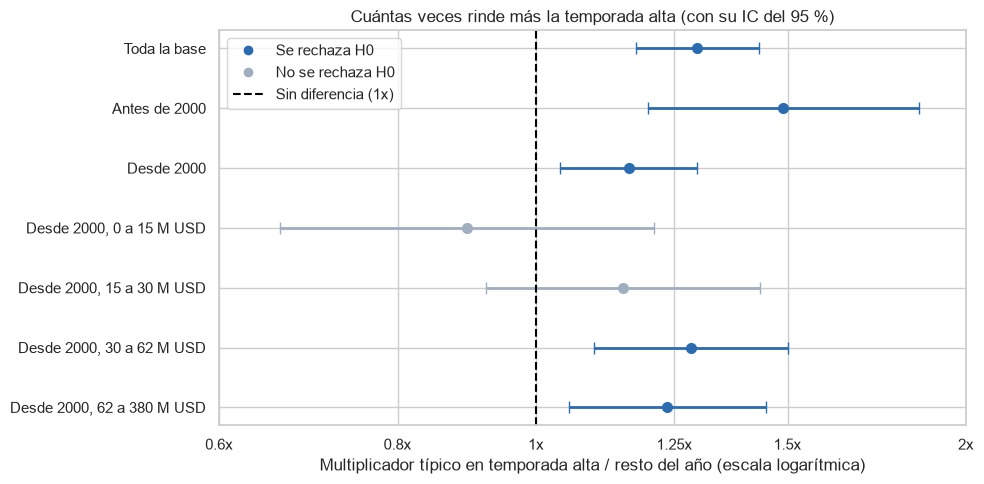

,Temporada alta,Resto del año,Diferencia del log,t de Welch,Grados de libertad,Valor p,Decisión,Rinde en temporada alta,IC 95 %,"Presupuesto mediano, Temporada alta (M USD)","Presupuesto mediano, Resto del año (M USD)"
Población,,,,,,,,,,,
Antes de 2000,572,367,0.173,3.58,629.9,3.7e-04,Se rechaza H0,1.49x,1.20x a 1.85x,20.0,12.0
"Desde 2000, 0 a 15 M USD",258,381,-0.048,-0.72,567.5,0.470,No se rechaza H0,0.89x,0.66x a 1.21x,8.0,7.0
"Desde 2000, 15 a 30 M USD",207,318,0.061,1.25,419.4,0.212,No se rechaza H0,1.15x,0.92x a 1.43x,23.0,24.0
"Desde 2000, 30 a 62 M USD",229,307,0.109,3.14,492.1,0.002,Se rechaza H0,1.28x,1.10x a 1.50x,44.0,43.0
"Desde 2000, 62 a 380 M USD",398,167,0.092,2.62,314.4,0.009,Se rechaza H0,1.24x,1.05x a 1.45x,100.0,90.0


In [16]:
subgrupos_h2 = {f"Antes de {ANIO_CORTE}": finanzas[finanzas["anio"] < ANIO_CORTE]}
subgrupos_h2.update({f"Desde {ANIO_CORTE}, {etiqueta} M USD": desde_2000[cuartil == etiqueta]
                     for etiqueta in etiquetas})

presupuestos = pd.DataFrame.from_dict(
    {nombre: datos.groupby("temporada")["budget"].median().div(1e6).round(1)
     for nombre, datos in subgrupos_h2.items()}, orient="index")
presupuestos = presupuestos[TEMPORADAS].add_prefix("Presupuesto mediano, ").add_suffix(" (M USD)")

comparadas = {"Toda la base": finanzas, f"Antes de {ANIO_CORTE}": subgrupos_h2[f"Antes de {ANIO_CORTE}"],
              f"Desde {ANIO_CORTE}": desde_2000}
comparadas.update({nombre: datos for nombre, datos in subgrupos_h2.items() if nombre.startswith("Desde")})
pruebas = {nombre: probar_welch(datos) for nombre, datos in comparadas.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for i, prueba in enumerate(pruebas.values()):
    veces, bajo, alto = 10 ** np.array([prueba["diferencia"], prueba["ic_bajo"], prueba["ic_alto"]])
    ax.errorbar(veces, i, xerr=[[veces - bajo], [alto - veces]], fmt="o", markersize=7, capsize=4,
                linewidth=2, color=AZUL if prueba["valor_p"] < ALFA else GRIS)
ax.axvline(1, color="black", linestyle="--", linewidth=1.5)
ax.set_yticks(range(len(pruebas)), list(pruebas))
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xticks([0.6, 0.8, 1, 1.25, 1.5, 2])
ax.minorticks_off()
ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}x"))
ax.legend(handles=[Line2D([], [], marker="o", color=AZUL, linestyle="", label="Se rechaza H0"),
                   Line2D([], [], marker="o", color=GRIS, linestyle="", label="No se rechaza H0"),
                   Line2D([], [], color="black", linestyle="--", label="Sin diferencia (1x)")],
          loc="upper left")
ax.set_title(f"Cuántas veces rinde más la temporada alta (con su IC del {CONFIANZA * 100:.0f} %)")
ax.set_xlabel("Multiplicador típico en temporada alta / resto del año (escala logarítmica)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

tabla_welch(subgrupos_h2).join(presupuestos)

**¿Qué vemos?** En la gráfica cada punto dice cuántas veces rinde más la temporada alta, y la línea horizontal es el intervalo de confianza del 95 %. Si la línea cruza el 1x, la diferencia no es significativa.

Lo primero es que la época sí infla el efecto. Antes de 2000 la diferencia del logaritmo es 0,173 (1,49 veces), más del doble que desde 2000. Y en esa época el 61 % de las películas de la base salió en temporada alta (572 de 939), mientras que desde 2000 es el 48 % (1.092 de 2.265). Como las películas viejas tienen multiplicadores más altos y están cargadas hacia la temporada alta, cuando se mezclan con las nuevas la ventaja se ve más grande de lo que es en el cine reciente.

Lo segundo, y lo que más nos llamó la atención, es que desde 2000 la ventaja depende del tamaño de la película:

- En los dos cuartiles más caros (de 30 a 62 millones y de más de 62) la temporada alta rinde 1,28 y 1,24 veces, con valores p de 0,002 y 0,009.
- En los dos más baratos no se rechaza H0. En las de hasta 15 millones el resultado incluso va al revés (0,89 veces, valor p de 0,470), y entre 15 y 30 millones da 1,15 veces con un valor p de 0,212.

Esto no pasa porque las de temporada alta sean más caras dentro de cada cuartil. El presupuesto mediano de los dos grupos queda parecido (por ejemplo, 44 contra 43 millones en el cuartil de 30 a 62). La única diferencia que se nota es en el más caro (100 contra 90 millones), y desde 2000 tener más presupuesto no da más multiplicador.

También se ve que las películas grandes se amontonan en esas fechas. En el cuartil más caro, 398 de 565 películas salieron en temporada alta, siete de cada diez. En el más barato fueron 258 de 639, cuatro de cada diez. Las grandes se pelean esas fechas y las pequeñas tienden a sacarles el cuerpo.

Sobre lo de hacer varias pruebas: si fuéramos más estrictos y le exigiéramos a cada una de las cinco un valor p menor que 0,05 / 5 = 0,01 (es la corrección de Bonferroni, que no está en las guías), seguirían siendo significativas la de antes de 2000 y la del cuartil de 30 a 62 millones, y la del más caro pasaría raspando, con 0,009.

En las baratas, la verdad, no hay datos suficientes para decidir. En el cuartil más barato el intervalo va de 0,66 a 1,21 veces, tan ancho que no podemos decir ni que la temporada alta les ayude ni que les haga daño. Lo único que podemos decir es que no encontramos evidencia de que les sirva.

#### Magnitud: ¿cuánto vale estrenar en temporada alta?

El valor p nos dice que la diferencia existe, pero no si es grande. Para ver cuánto pesa comparamos los dos grupos con el **multiplicador típico**, que es el promedio del logaritmo devuelto a la escala normal (en estadística se llama media geométrica y no está en las guías). También miramos los cuartiles del multiplicador, el porcentaje de películas que perdieron plata (multiplicador menor a 1) y el de rentables.

In [17]:
negocio = {}
for nombre, datos in poblaciones_h2.items():
    for temporada in TEMPORADAS:
        grupo = datos[datos["temporada"] == temporada]
        multiplicador = grupo["multiplicador"]
        negocio[(nombre, temporada)] = {
            "Películas": len(grupo),
            "Multiplicador típico": round(10 ** np.log10(multiplicador).mean(), 2),
            "Multiplicador Q1": round(multiplicador.quantile(0.25), 2),
            "Multiplicador mediano": round(multiplicador.median(), 2),
            "Multiplicador Q3": round(multiplicador.quantile(0.75), 2),
            "% perdieron plata": round((multiplicador < 1).mean() * 100, 1),
            "% rentables": round(grupo["rentable"].mean() * 100, 1),
        }

pd.DataFrame.from_dict(negocio, orient="index").rename_axis(["Población", "Temporada"])

Películas  Multiplicador típico  \
Población    Temporada                                         
Toda la base Temporada alta       1664                  2.31   
             Resto del año        1540                  1.78   
Desde 2000   Temporada alta       1092                  1.95   
             Resto del año        1173                  1.68   

                             Multiplicador Q1  Multiplicador mediano  \
Población    Temporada                                                 
Toda la base Temporada alta              1.26                   2.64   
             Resto del año               0.86                   2.02   
Desde 2000   Temporada alta              1.10                   2.30   
             Resto del año               0.87                   1.97   

                             Multiplicador Q3  % perdieron plata  % rentables  
Población    Temporada                                                         
Toda la base Temporada alta              4.75               20.0         61.4  
             Resto del año               4.08               28.8         50.6  
Desde 2000   Temporada alta              4.09               22.2         57.1  
             Resto del año               3.71               28.8         49.6

**¿Qué vemos?** Nos fijamos sobre todo en las películas desde 2000, que son las que le sirven de referencia a una productora hoy.

El retorno típico sube, pero no mucho. El multiplicador típico es 1,95 en temporada alta y 1,68 en el resto del año, que es justo la diferencia de 1,16 veces de la prueba. La mediana pasa de 1,97 a 2,30.

Donde más se nota es en las películas a las que les va mal. El cuartil 1 pasa de 0,87 a 1,10: fuera de temporada más de una cuarta parte de las películas no recupera lo que costó, y en temporada alta son menos de una cuarta parte. El porcentaje que perdió plata baja de 28,8 % a 22,2 % y el de rentables sube de 49,6 % a 57,1 %. Arriba la diferencia es menor, porque el cuartil 3 solo pasa de 3,71 a 4,09. Entonces en temporada alta los éxitos no son mucho más grandes, lo que pasa es que hay menos fracasos.

Y la diferencia es pequeña si se compara con lo mucho que varían las películas. La diferencia de promedios del logaritmo (0,065) es como la décima parte de la desviación estándar de cada grupo (0,551 y 0,610). Los dos grupos se traslapan casi completos, así que saber en qué temporada salió una película dice muy poco de cómo le fue a esa película en particular.

En toda la base la diferencia es más grande (multiplicador típico de 2,31 contra 1,78, y 20,0 % contra 28,8 % de películas que perdieron plata), pero como ya vimos, parte de eso lo ponen las películas viejas.

#### Conclusión de la hipótesis 2

| Población | Películas (alta / resto) | Diferencia del log | Valor p | Rinde en temporada alta (IC 95 %) | Decisión |
|---|---|---|---|---|---|
| Toda la base | 1.664 / 1.540 | 0,113 | 2,8 × 10⁻⁷ | 1,30 veces (1,17 a 1,43) | Se rechaza H0 |
| Desde 2000 | 1.092 / 1.173 | 0,065 | 0,008 | 1,16 veces (1,04 a 1,30) | Se rechaza H0 |

**Respuesta a la pregunta de negocio: ¿cuándo estrenar?** Sí encontramos evidencia de que las películas que se estrenan en temporada alta rinden más por cada dólar invertido, y a diferencia de la hipótesis 1, esto se mantiene en el cine reciente. Es el primero de los escenarios que planteamos en la sección 1.4. Pero el efecto no es tan grande: desde 2000 son más o menos un 16 % más de multiplicador típico, 7,5 puntos más de películas rentables y 6,6 puntos menos de películas que pierden plata. Y no les pasa igual a todas, porque la ventaja está sobre todo en las películas de más de 30 millones.

Para la productora eso quiere decir que la recomendación depende del tamaño de la película. Si se va a meter en una de más de 30 millones, vale la pena pelear una fecha de verano (el de Estados Unidos) o de fin de año, aunque cueste más conseguirla. Si hace películas pequeñas, que es lo más probable con poco capital, no encontramos evidencia de que pagar más o esperar por esas fechas mejore el retorno. En ese caso la fecha se puede escoger con otros criterios, por ejemplo no chocar con las películas grandes, que se amontonan en esas fechas.

Como rechazamos H0, el error que podríamos estar cometiendo es el tipo I, o sea ver una diferencia que en realidad no existe. Ese riesgo lo fijamos en 5 % con α, y la diferencia aparece tanto en toda la base como desde 2000. En los cuartiles baratos, donde no rechazamos, el riesgo es el contrario, el tipo II: con menos películas y un intervalo tan ancho, se nos pudo pasar una ventaja que sí existe.

**Lo que no podemos concluir:**

- Que la fecha sea la causa. Los estudios guardan la temporada alta para las películas en las que más confían (secuelas, franquicias, las que tienen más publicidad), así que ese grupo ya viene escogido. Comparar dentro de cada cuartil de presupuesto controla lo que costó la película, pero no la publicidad ni qué tan conocida era antes de salir. Mover una película para julio no garantiza que rinda un 16 % más.
- La prueba compara el promedio del logaritmo, o sea el multiplicador típico. Los porcentajes de rentables y de películas que perdieron plata los comparamos solo de forma descriptiva, no les hicimos una prueba aparte.
- En TMDB, `release_date` suele ser el primer estreno que aparece registrado, que puede ser un festival o el estreno en otro país. Entonces algunas películas pueden haber quedado en el grupo que no era.
- La temporada alta la definimos con el calendario de Estados Unidos. Dentro de esa temporada no todos los meses son iguales (agosto queda por debajo de la mediana general, sección 1.4), y para estrenar en otro mercado las mejores fechas pueden ser otras.
- Lo de los cuartiles se hizo con grupos más pequeños y sumando pruebas. Las diferencias de los cuartiles caros aguantan un criterio más estricto, pero que en los baratos no aparezca nada puede ser porque faltan datos. Por eso con las películas pequeñas somos cautelosos: no encontramos evidencia a favor, pero tampoco evidencia en contra.
- La base solo tiene las películas que reportaron cifras, que suelen ser las más comerciales, y los montos están en dólares de cada año, sin ajustar por inflación (aunque al multiplicador eso casi no lo afecta).

### 2.3 Prueba de la hipótesis 3: género y rentabilidad

Lo que vamos a probar:

- **H0:** el género principal y ser rentable son independientes, es decir, la proporción de películas rentables es la misma en todos los géneros.
- **H1:** el género principal y ser rentable están asociados: al menos un género tiene una proporción de rentables distinta.

Usamos `genero_agrupado`, del notebook 02 (el género principal, con los géneros de menos de 50 películas en "Otros"), y `rentable` (multiplicador de 2 o más). Igual que en las hipótesis 1 y 2, corremos la prueba sobre toda la base financiera y solo con las películas desde 2000. En las dos dejamos los mismos 12 grupos, para que se puedan comparar.

#### Supuestos

La chi-cuadrado de independencia (guía de la semana 6) pide dos cosas. La primera es que las observaciones sean independientes: cada película tiene que contar una sola vez, y por eso usamos el género principal y no todos sus géneros. La segunda es que la frecuencia esperada de cada casilla de la tabla sea mayor que 5. La frecuencia esperada es la cantidad de películas que caería en esa casilla si el género no tuviera nada que ver con ser rentable: el total de películas del género multiplicado por el porcentaje general de rentables. La película de la base que no tiene género queda por fuera.

#### Prueba chi-cuadrado de independencia

El estadístico suma, casilla por casilla, qué tanto se aleja lo observado de lo esperado: χ² = Σ (O − E)² / E, con (12 − 1) × (2 − 1) = 11 grados de libertad. Lo calculamos con `scipy.stats.chi2_contingency` y, como en las otras pruebas, revisamos que dé lo mismo que la fórmula. Le pasamos `correction=False` para que use exactamente esa fórmula también en las tablas de 2 × 2 que hacemos más abajo; por defecto `scipy` les aplica a esas tablas una corrección que no está en las guías.

La chi-cuadrado dice si hay asociación, pero no qué tan fuerte es. Para eso calculamos la V de Cramér, V = √(χ² / (n · (k − 1))), donde n es el número de películas y k el menor entre el número de filas y de columnas (aquí k = 2). Va de 0, cuando no hay ninguna asociación, a 1, cuando el género define por completo si la película es rentable. Como dijimos en la sección 1.5, no está en las guías y la consultamos aparte.

In [18]:
MIN_FRECUENCIA_ESPERADA = 5

poblaciones_h3 = {nombre: datos.dropna(subset=["genero_agrupado"])
                  for nombre, datos in poblaciones_h1.items()}


def decidir(valor_p):
    return "Se rechaza H0" if valor_p < ALFA else "No se rechaza H0"


def tabla_contingencia(datos, columna="genero_agrupado"):
    observadas = pd.crosstab(datos[columna], datos["rentable"])
    return observadas.rename(columns={False: "No rentable", True: "Rentable"})


def probar_chi2(observadas):
    resultado = stats.chi2_contingency(observadas, correction=False)
    esperadas = resultado.expected_freq
    chi2 = ((observadas - esperadas) ** 2 / esperadas).to_numpy().sum()
    assert np.isclose(chi2, resultado.statistic), "El chi-cuadrado no coincide con la fórmula"
    n = observadas.to_numpy().sum()
    return {
        "Películas": n,
        "Grupos": len(observadas),
        "Esperada mínima": round(esperadas.min(), 1),
        "Chi-cuadrado": round(chi2, 2),
        "Grados de libertad": resultado.dof,
        "Valor p": formatear_p(resultado.pvalue),
        "V de Cramér": round(np.sqrt(chi2 / (n * (min(observadas.shape) - 1))), 3),
        "Decisión": decidir(resultado.pvalue),
    }


for nombre, datos in poblaciones_h3.items():
    print(f"Rentables ({nombre.lower()}): {datos['rentable'].mean():.1%}")

pd.DataFrame({nombre: probar_chi2(tabla_contingencia(datos))
              for nombre, datos in poblaciones_h3.items()}).T.rename_axis("Población")

Rentables (toda la base): 56.2%
Rentables (desde 2000): 53.3%


,Películas,Grupos,Esperada mínima,Chi-cuadrado,Grados de libertad,Valor p,V de Cramér,Decisión
Población,,,,,,,,
Toda la base,3203,12,30.2,55.65,11,5.9e-08,0.132,Se rechaza H0
Desde 2000,2264,12,22.9,48.76,11,1.0e-06,0.147,Se rechaza H0


**¿Qué vemos?** Los supuestos se cumplen sin problema. El porcentaje general de rentables es 56,2 % en toda la base y 53,3 % desde 2000, y con esos porcentajes la frecuencia esperada más baja queda en 30,2 y 22,9, muy por encima de 5. En la sección 1.5 habíamos calculado que la más baja rondaría 30.

Se rechaza H0 en las dos poblaciones. En toda la base χ² = 55,65 con 11 grados de libertad y un valor p de 5,9 × 10⁻⁸; desde 2000, χ² = 48,76 con un valor p de 1,0 × 10⁻⁶. Hay evidencia de que la proporción de películas rentables no es la misma en todos los géneros y, a diferencia de la hipótesis 1, el resultado se mantiene en el cine reciente.

Pero la asociación es débil. La V de Cramér da 0,132 en toda la base y 0,147 desde 2000, mucho más cerca de 0 que de 1: saber el género de una película ayuda poco a adivinar si va a ser rentable. Como en las otras pruebas, con más de 2.000 películas una asociación así de pequeña ya sale significativa. Falta ver de dónde sale.

#### ¿Qué géneros mueven el resultado?

La chi-cuadrado no tiene dirección: si sale significativa, solo dice que algún género se aleja de lo esperado, pero no cuál. Para verlo comparamos, en cada género, las películas rentables que hay con las que se esperarían si el género no importara, y calculamos qué parte del chi-cuadrado total aporta cada uno (la suma de sus dos casillas, rentable y no rentable).

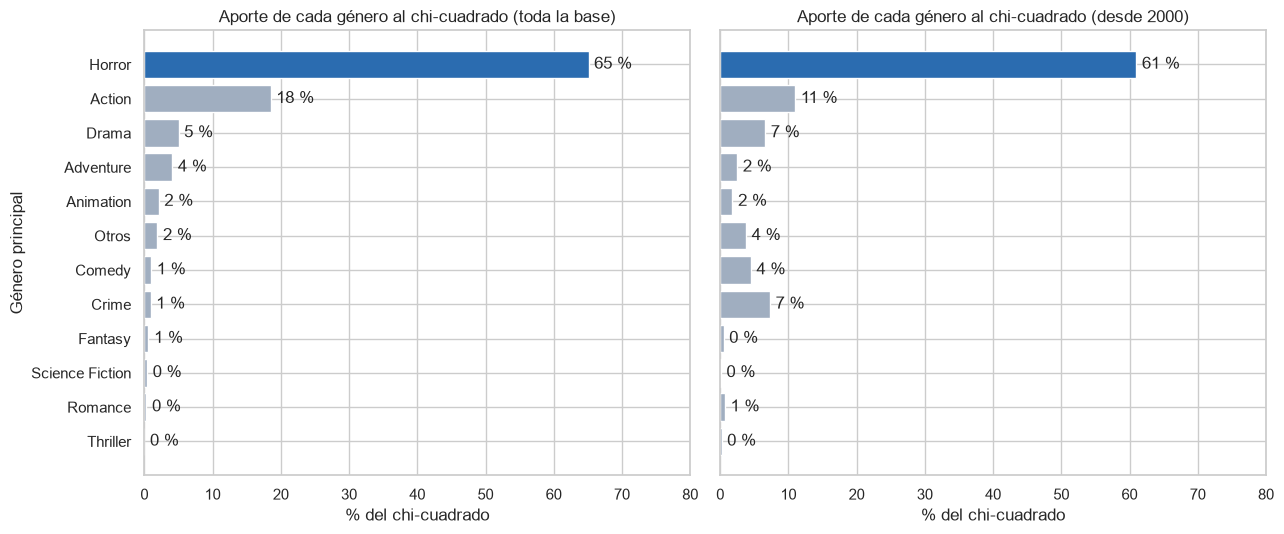

Toda la base                                            \
                   Películas Rentables Rentables esperadas % rentables   
genero_agrupado                                                          
Horror                   196       152               110.2        77.6   
Action                   588       292               330.6        49.7   
Drama                    737       392               414.4        53.2   
Adventure                287       174               161.4        60.6   
Animation                 99        61                55.7        61.6   
Otros                    172        90                96.7        52.3   
Comedy                   629       363               353.7        57.7   
Crime                    141        75                79.3        53.2   
Fantasy                   91        54                51.2        59.3   
Science Fiction           78        46                43.9        59.0   
Romance                   69        37                38.8        53.6   
Thriller                 116        65                65.2        56.0   

                                   Desde 2000                                \
                % del chi-cuadrado  Películas Rentables Rentables esperadas   
genero_agrupado                                                               
Horror                        65.1        125        97                66.6   
Action                        18.5        412       196               219.5   
Drama                          5.0        519       256               276.5   
Adventure                      4.1        185       106                98.5   
Animation                      2.1         84        49                44.7   
Otros                          1.9        121        57                64.5   
Comedy                         1.0        464       263               247.2   
Crime                          0.9         90        39                47.9   
Fantasy                        0.6         64        36                34.1   
Science Fiction                0.4         49        27                26.1   
Romance                        0.3         49        24                26.1   
Thriller                       0.0        102        56                54.3   

                                                
                % rentables % del chi-cuadrado  
genero_agrupado                                 
Horror                 77.6               61.0  
Action                 47.6               11.0  
Drama                  49.3                6.6  
Adventure              57.3                2.5  
Animation              58.3                1.8  
Otros                  47.1                3.8  
Comedy                 56.7                4.5  
Crime                  43.3                7.3  
Fantasy                56.2                0.5  
Science Fiction        55.1                0.1  
Romance                49.0                0.7  
Thriller               54.9                0.2

In [19]:
def aportes_por_genero(datos):
    observadas = tabla_contingencia(datos)
    esperadas = pd.DataFrame(stats.contingency.expected_freq(observadas),
                             index=observadas.index, columns=observadas.columns)
    aporte = ((observadas - esperadas) ** 2 / esperadas).sum(axis=1)
    return pd.DataFrame({
        "Películas": observadas.sum(axis=1),
        "Rentables": observadas["Rentable"],
        "Rentables esperadas": esperadas["Rentable"].round(1),
        "% rentables": (observadas["Rentable"] / observadas.sum(axis=1) * 100).round(1),
        "% del chi-cuadrado": (aporte / aporte.sum() * 100).round(1),
    })


aportes = {nombre: aportes_por_genero(datos) for nombre, datos in poblaciones_h3.items()}
orden = aportes["Toda la base"].sort_values("% del chi-cuadrado").index

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, (nombre, tabla) in zip(ejes, aportes.items()):
    valores = tabla.loc[orden, "% del chi-cuadrado"]
    barras = ax.barh(orden, valores, color=[AZUL if valor == valores.max() else GRIS for valor in valores])
    ax.bar_label(barras, labels=[f"{valor:.0f} %" for valor in valores], padding=4)
    ax.set_xlim(0, 80)
    ax.set_title(f"Aporte de cada género al chi-cuadrado ({nombre.lower()})")
    ax.set_xlabel("% del chi-cuadrado")
ejes[0].set_ylabel("Género principal")
plt.tight_layout()
plt.show()

pd.concat(aportes, axis=1).loc[orden[::-1]]

**¿Qué vemos?** Casi todo el chi-cuadrado lo pone un solo género: terror (*Horror*) aporta el 65,1 % en toda la base y el 61,0 % desde 2000. Tiene 152 películas rentables cuando se esperaban 110,2 si el género no importara, o sea que el 77,6 % de sus películas es rentable, contra el 56,2 % general. Desde 2000 su porcentaje es el mismo, 77,6 %, contra 53,3 %.

El segundo es acción (*Action*), pero por el lado contrario y con mucho menos peso: 292 rentables cuando se esperaban 330,6 (49,7 %), y aporta el 18,5 % del chi-cuadrado. Desde 2000 su aporte baja al 11,0 %, y el género con menos rentables pasa a ser crimen (*Crime*), con 43,3 %, aunque solo aporta el 7,3 %. En toda la base, los otros diez grupos aportan entre 0,0 % y 5,0 % cada uno, y sus porcentajes de rentables quedan entre 52,3 % y 61,6 %, cerca del general.

Si terror explica casi todo, la pregunta es si sin él quedaría alguna asociación. Para comprobarlo repetimos la prueba con los otros 11 grupos:

In [20]:
genero_dominante = aportes["Toda la base"]["% del chi-cuadrado"].idxmax()
sin_dominante = {nombre: datos[datos["genero_agrupado"] != genero_dominante]
                 for nombre, datos in poblaciones_h3.items()}

pd.DataFrame({nombre: probar_chi2(tabla_contingencia(datos))
              for nombre, datos in sin_dominante.items()}).T.rename_axis(f"Población, sin {genero_dominante}")

,Películas,Grupos,Esperada mínima,Chi-cuadrado,Grados de libertad,Valor p,V de Cramér,Decisión
"Población, sin Horror",,,,,,,,
Toda la base,3007,11,31.2,16.98,10,0.075,0.075,No se rechaza H0
Desde 2000,2139,11,23.6,17.25,10,0.069,0.09,No se rechaza H0


**¿Qué vemos?** Sin terror ya no se rechaza H0: el valor p sube a 0,075 en toda la base y a 0,069 desde 2000, los dos por encima de 0,05, y la V de Cramér baja a 0,075 y 0,09. No encontramos evidencia de que los demás géneros se diferencien entre sí en la probabilidad de ser rentables; las diferencias que se ven entre ellos, como el 49,7 % de acción frente al 60,6 % de aventura, pueden ser variación normal.

Hay que leer esto con cuidado. Esta prueba la hicimos después de ver el resultado principal, para entender de dónde salía la asociación, así que la tomamos como una revisión y no como una hipótesis nueva. Y como los valores p quedan cerca de 0,05, no decimos que entre los demás géneros no haya ninguna diferencia: decimos que con estos datos no alcanzamos a verla.

#### ¿Es el género o el presupuesto?

En la sección 1.5 dejamos anotada una duda: terror es el género grande más barato (presupuesto mediano de 10,9 millones, contra 44 de acción), así que su ventaja podría venir del presupuesto y no del género. La hipótesis 1 ya dio una pista, porque desde 2000 el presupuesto no tiene correlación con el multiplicador, pero lo revisamos directamente. Dentro de cada cuartil de presupuesto desde 2000 (los mismos de las secciones 2.1 y 2.2) comparamos terror contra el resto de géneros con una chi-cuadrado de 2 × 2. Si la ventaja fuera solo del presupuesto, debería desaparecer al comparar películas que costaron parecido.

Solo corremos la prueba donde la frecuencia esperada mínima es de al menos 5. Y como son varias pruebas, nos pasa lo mismo que en la hipótesis 2: las tomamos como una revisión del resultado principal.

In [21]:
con_cuartil = poblaciones_h3[f"Desde {ANIO_CORTE}"].assign(
    cuartil=cuartil, es_dominante=lambda datos: datos["genero_agrupado"].eq(genero_dominante))

filas = {}
for etiqueta in etiquetas:
    datos = con_cuartil[con_cuartil["cuartil"] == etiqueta]
    prueba = probar_chi2(tabla_contingencia(datos, "es_dominante"))
    aplica = prueba["Esperada mínima"] >= MIN_FRECUENCIA_ESPERADA
    rentables = datos.groupby("es_dominante")["rentable"].mean() * 100
    filas[f"{etiqueta} M USD"] = {
        f"Películas de {genero_dominante}": int(datos["es_dominante"].sum()),
        f"% rentables {genero_dominante}": round(rentables[True], 1),
        "% rentables resto": round(rentables[False], 1),
        "Esperada mínima": prueba["Esperada mínima"],
        "Valor p": prueba["Valor p"] if aplica else "No aplica",
        "Decisión": prueba["Decisión"] if aplica else "No aplica",
    }

pd.DataFrame.from_dict(filas, orient="index").rename_axis(f"Presupuesto (desde {ANIO_CORTE})")

,Películas de Horror,% rentables Horror,% rentables resto,Esperada mínima,Valor p,Decisión
Presupuesto (desde 2000),,,,,,
0 a 15 M USD,75,82.7,51.5,33.6,3.5e-07,Se rechaza H0
15 a 30 M USD,26,80.8,46.7,12.6,7.0e-04,Se rechaza H0
30 a 62 M USD,20,65.0,47.9,9.7,0.133,No se rechaza H0
62 a 380 M USD,4,25.0,60.4,1.6,No aplica,No aplica


**¿Qué vemos?** La ventaja de terror no desaparece cuando se comparan películas de presupuesto parecido. En el cuartil más barato (hasta 15 millones) el 82,7 % de las películas de terror es rentable, contra el 51,5 % del resto, con un valor p de 3,5 × 10⁻⁷. Entre 15 y 30 millones pasa lo mismo: 80,8 % contra 46,7 %, con un valor p de 7,0 × 10⁻⁴. Las dos se mantienen aunque les exijamos un valor p menor que 0,05 / 3 = 0,017, con la corrección de Bonferroni que usamos en la hipótesis 2.

Entre 30 y 62 millones terror sigue arriba (65,0 % contra 47,9 %), pero con solo 20 películas no se rechaza H0 (valor p de 0,133). En el cuartil más caro hay apenas 4 películas de terror y la frecuencia esperada mínima es 1,6, así que no se cumple el supuesto y no corremos la prueba.

La tabla también muestra cómo se hace el cine de terror: de las películas de terror desde 2000, 75 están en el cuartil más barato y solo 4 en el más caro. Su ventaja está justo en el rango de presupuesto en el que se mueve una productora con capital limitado.

#### Conclusión de la hipótesis 3

| Población | Películas | χ² (11 gl) | Valor p | V de Cramér | Decisión |
|---|---|---|---|---|---|
| Toda la base | 3.203 | 55,65 | 5,9 × 10⁻⁸ | 0,132 | Se rechaza H0 |
| Desde 2000 | 2.264 | 48,76 | 1,0 × 10⁻⁶ | 0,147 | Se rechaza H0 |

**Respuesta a la pregunta de negocio: ¿qué tipo de película hacer?** Sí encontramos evidencia de que el género está asociado con la probabilidad de ser rentable, y se mantiene en el cine reciente. Es el primer escenario que planteamos en la sección 1.5. Pero la asociación es débil y casi toda la explica un solo género: terror, con el 77,6 % de películas rentables contra el 56,2 % general. Esa ventaja se mantiene al comparar películas de presupuesto parecido, por lo menos hasta los 30 millones. Entre los demás géneros no encontramos evidencia de diferencias.

Para la productora eso quiere decir que terror es la apuesta con más probabilidad de recaudar el doble de lo que cuesta, y además es un género que se hace con poca plata, que es justo lo que ella tiene. En los demás géneros, el género por sí solo no es un buen criterio para escoger, y la decisión se puede apoyar en otras cosas, como el público al que quiere llegar, el talento que consiga o la fecha de estreno (hipótesis 2).

Como rechazamos H0, el error que podríamos estar cometiendo es el tipo I, o sea ver una asociación que no existe. Ese riesgo lo fijamos en 5 % con α, pero el valor p queda muy por debajo y el resultado aparece en las dos poblaciones y dentro de los cuartiles baratos. En la prueba sin terror es al revés: no rechazamos, así que el riesgo es el tipo II, que haya diferencias entre los otros géneros que no alcanzamos a ver.

**Lo que no podemos concluir:**

- Que hacer una película de terror garantice que sea rentable, ni que el género sea la causa. Casi una de cada cuatro películas de terror de la base no fue rentable, y detrás de la diferencia puede haber otras cosas, como un público fiel al género o presupuestos muy controlados.
- El género principal es el primero que lista TMDB, y no siempre es el que mejor describe la película: una película de terror y comedia que aparezca primero como comedia quedó contada como comedia.
- La chi-cuadrado solo mira si la película es rentable o no, con el umbral de 2x. No dice cuánto más rinden las de terror; eso lo vimos solo de forma descriptiva (multiplicador mediano de 3,7 en la sección 1.5).
- La base solo tiene películas que reportaron cifras, y una película pequeña de terror que fracasó tiene menos probabilidad de reportar su taquilla. Si eso pasa más en terror que en otros géneros, su ventaja real sería menor que la que vemos.
- La prueba sin terror y la de los cuartiles las hicimos después de ver el resultado principal: sirven para entenderlo, no como hipótesis independientes.

## 3. Síntesis de resultados

Con las tres pruebas listas, juntamos los resultados para volver a las tres preguntas clave del notebook 01. La tabla la arma el código con las mismas funciones de cada prueba, así que las cifras son las de las secciones 2.1, 2.2 y 2.3. Para cada hipótesis ponemos el efecto en la medida de su prueba: el ρ de Spearman, cuántas veces es mayor el multiplicador típico en temporada alta y la V de Cramér.

In [22]:
def fila_sintesis(prueba, efecto, valor_p, decision):
    return {"Prueba": prueba, "Efecto": efecto, "Valor p": valor_p, "Decisión": decision}


sintesis = {}
for nombre, datos in poblaciones_h1.items():
    h1 = probar_spearman(datos)
    sintesis[("H1: presupuesto", nombre)] = fila_sintesis(
        "Correlación de Spearman", f"ρ = {h1['ρ de Spearman']}", h1["Valor p"], h1["Decisión"])
for nombre, datos in poblaciones_h2.items():
    h2 = probar_welch(datos)
    sintesis[("H2: temporada", nombre)] = fila_sintesis(
        "t de Welch", f"{10 ** h2['diferencia']:.2f}x en temporada alta",
        formatear_p(h2["valor_p"]), decidir(h2["valor_p"]))
for nombre, datos in poblaciones_h3.items():
    h3 = probar_chi2(tabla_contingencia(datos))
    sintesis[("H3: género", nombre)] = fila_sintesis(
        "Chi-cuadrado", f"V de Cramér = {h3['V de Cramér']}", h3["Valor p"], h3["Decisión"])

pd.DataFrame.from_dict(sintesis, orient="index").rename_axis(["Hipótesis", "Población"])

Prueba  \
Hipótesis       Población                               
H1: presupuesto Toda la base  Correlación de Spearman   
                Desde 2000    Correlación de Spearman   
H2: temporada   Toda la base               t de Welch   
                Desde 2000                 t de Welch   
H3: género      Toda la base             Chi-cuadrado   
                Desde 2000               Chi-cuadrado   

                                               Efecto  Valor p  \
Hipótesis       Población                                        
H1: presupuesto Toda la base              ρ = -0.1368  7.5e-15   
                Desde 2000                ρ = -0.0001    0.996   
H2: temporada   Toda la base  1.30x en temporada alta  2.8e-07   
                Desde 2000    1.16x en temporada alta    0.008   
H3: género      Toda la base      V de Cramér = 0.132  5.9e-08   
                Desde 2000        V de Cramér = 0.147  1.0e-06   

                                      Decisión  
Hipótesis       Población                       
H1: presupuesto Toda la base     Se rechaza H0  
                Desde 2000    No se rechaza H0  
H2: temporada   Toda la base     Se rechaza H0  
                Desde 2000       Se rechaza H0  
H3: género      Toda la base     Se rechaza H0  
                Desde 2000       Se rechaza H0

**¿Qué vemos?** De las seis pruebas, solo una no rechaza H0: la del presupuesto desde 2000. Pero los valores p no se pueden leer solos. En las tres hipótesis el efecto es pequeño, y en la 1 el resultado de toda la base se cae al quitar las películas viejas.

| Pregunta clave | Hipótesis | Lo que encontramos (desde 2000) | Lo que le sirve a la productora |
|---|---|---|---|
| 1. ¿Meterle más presupuesto a una película hace que rinda más por cada dólar invertido? | H1, correlación de Spearman | No hay evidencia de correlación (ρ = −0,0001, valor p de 0,996). La correlación negativa de toda la base viene de las películas de antes de 2000 | El presupuesto no cambia el retorno típico, pero sí el riesgo: las películas baratas pierden plata más seguido (comparación descriptiva). Con poco capital conviene repartirlo en varias películas pequeñas |
| 2. ¿Estrenar en temporada alta mejora el retorno de una película? | H2, t de Welch | Sí: el multiplicador típico es 1,16 veces mayor en temporada alta (valor p de 0,008), sobre todo en películas de más de 30 millones | Para películas grandes vale la pena pelear esas fechas; para las pequeñas no encontramos evidencia de que sirvan |
| 3. ¿El género influye en la probabilidad de que una película sea rentable? | H3, chi-cuadrado | Sí, pero débil (V de Cramér = 0,147, valor p de 1,0 × 10⁻⁶), y casi todo lo explica terror (77,6 % de rentables, también con presupuesto parecido) | Terror es el género con más probabilidad de ser rentable y se hace con poca plata; entre los demás géneros no hay evidencia de diferencias |

Las tres respuestas encajan entre sí. A una productora con capital limitado le va a tocar hacer películas de presupuesto bajo, donde el riesgo de perder plata es más alto y donde no encontramos evidencia de que la temporada alta ayude, pero donde el terror se destaca. Las tres pruebas tienen las mismas limitaciones de base: muestran asociación y no causalidad, la base solo tiene las películas que reportaron cifras y la definición de rentable es una aproximación. En el notebook 05 usamos estos resultados, junto con los KPIs, para proponer las decisiones.